## Reconocimiento

Instala todo lo necesario para que el notebook corra con *Run All* en una máquina nueva.

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn nltk langdetect emoji emosent-py simplemma sentence-transformers keras scikeras spacy

import sys
!{sys.executable} -m spacy download es_core_news_sm -q

import os
os.environ["KERAS_BACKEND"] = "torch"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ValidationCurveDisplay
import pandas as pd
from langdetect import detect, DetectorFactory
import matplotlib.pyplot as plt
import unicodedata
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, classification_report, confusion_matrix, \
    ConfusionMatrixDisplay
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
from langdetect import LangDetectException
import re
from sklearn.model_selection import train_test_split
import emoji
import simplemma
from nltk import word_tokenize
from emosent import get_emoji_sentiment_rank




C:\Users\nicky\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
url = "https://raw.githubusercontent.com/LucasFis/Tp_tweets/main/ia_tweets.csv"

df = pd.read_csv(url)

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [4]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [5]:
DetectorFactory.seed = 0

def idioma(texto):
    try:
        return detect(str(texto))
    except LangDetectException:
        return "es"

df['idioma'] = df['text'].map(idioma)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

print("Tweets conservados:", len(df))

Tweets conservados: 3660


**Filtro de idioma y columnas descartadas**

- El dataset tiene tweets en otros idiomas (inglés, portugués, etc.). Los sacamos porque los modelos de texto que usamos (stopwords, stemmer y el modelo de embeddings) son todos para español, así que un tweet en inglés sería ruido.
- `DetectorFactory.seed = 0`: `langdetect` es aleatorio por dentro y, sin semilla, el mismo tweet puede dar distinto idioma en cada corrida. Con la semilla el resultado es reproducible.
- Si `langdetect` falla (por ejemplo, un tweet que es solo un link o solo emojis), asumimos que está en español. Preferimos quedarnos con ese tweet antes que perderlo, ya que casi todo el dataset está en español.
- Pasamos de 4038 a 3660 tweets: se fue ~9%.

Columnas que tiramos:
- `ID`: es un identificador y no dice nada del sentimiento.
- `user_is_translator` y `user_protected`: valen 0 en todos los tweets, así que no aportan información.
- `user_has_extended_profile`: es un detalle del usuario y no tiene relación con lo que dice el tweet.

In [6]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


**Las clases están muy desbalanceadas** (~66% neutros, ~19% positivos, ~15% negativos), y esto define varias decisiones:

- Un modelo que siempre diga `NEU` ya tendría 66% de *accuracy*. Por eso **no usamos accuracy para elegir modelos** y usamos **F1 macro**, que promedia el F1 de cada clase dándole el mismo peso a las tres.
- En los grids probamos `class_weight="balanced"`, que hace que equivocarse en una clase minoritaria "cueste" más.

In [7]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [8]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


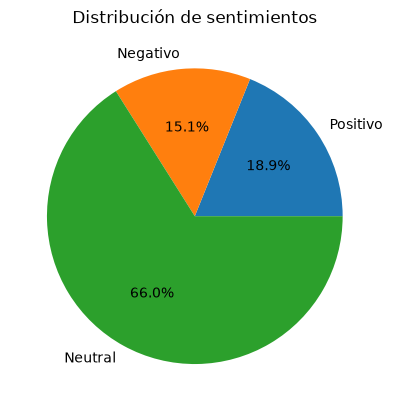

In [9]:
# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


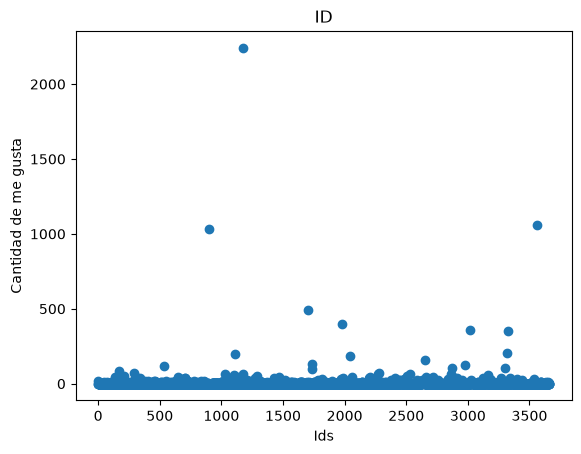

In [10]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


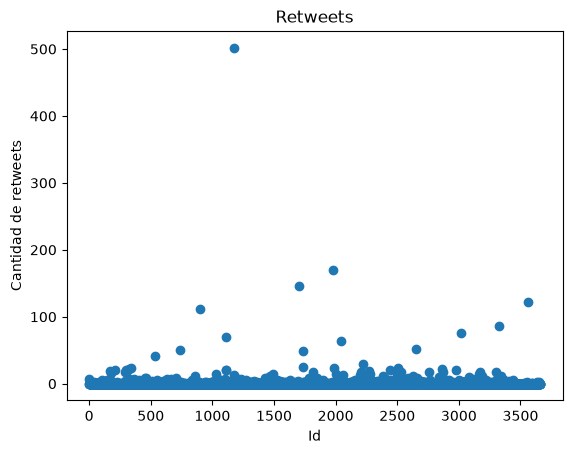

In [11]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


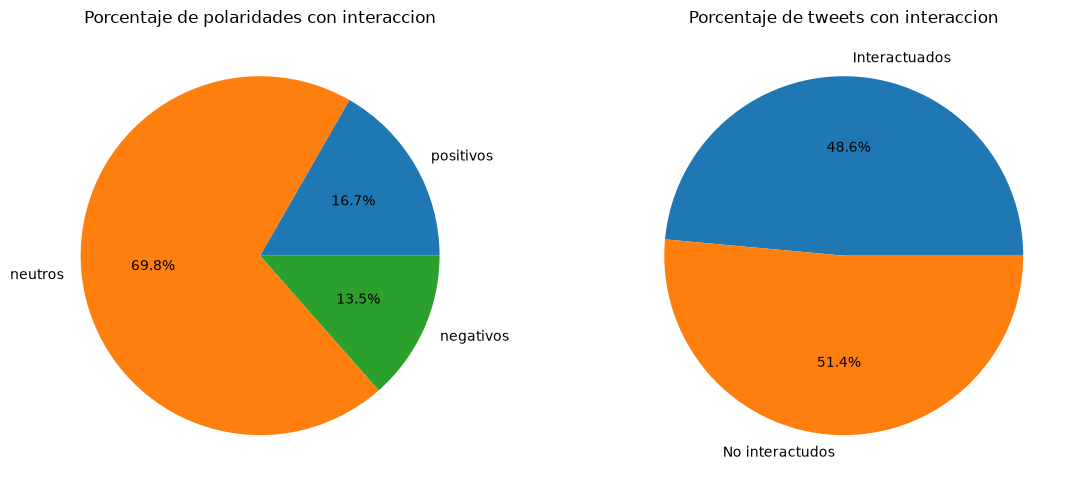

In [12]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

## Feature Engineering

In [13]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)


def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["interrogation_count"] = df['text'].apply(lambda texto: texto.count('?') )
df["exclamation_count"] = df['text'].apply(lambda texto: texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de interrogacion
#Cantidad de signos de exclamacion

In [14]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")


def _separar_hashtag(match):
    """#InteligenciaArtificial -> Inteligencia Artificial."""
    palabra = match.group(1)
    return " " + re.sub(r"(?<=[a-záéíóúüñ])(?=[A-ZÁÉÍÓÚÑ])", " ", palabra) + " "


def normalizar_texto(texto):
    """Normaliza sin perder informacion util para el modelo.

    - NFC conserva tildes y enes en una forma canonica.
    - URLs, menciones y hashtags se reemplazan por tokens explicitos.
    - El hashtag conserva su palabra para no perder el tema del tweet.
    """
    texto = unicodedata.normalize("NFC", str(texto))
    texto = URL_RE.sub(" URL ", texto)
    texto = MENTION_RE.sub(" MENCION ", texto)
    texto = HASHTAG_RE.sub(_separar_hashtag, texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


df["text"] = df["text"].map(normalizar_texto)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,interrogation_count,exclamation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0,0


**Normalización del texto**

- **Links → `URL` y menciones → `MENCION`**: el link exacto o el nombre del usuario no dicen nada del sentimiento y solo inflan el vocabulario (cada usuario sería una "palabra" distinta). Pero que haya un link o una mención sí puede importar, por eso los reemplazamos por un token en lugar de borrarlos.
- **Hashtags**: sacamos el `#` y separamos las palabras pegadas (`#InteligenciaArtificial` → `Inteligencia Artificial`), así el modelo entiende el contenido del hashtag como palabras normales.
- **NFC**: unifica cómo se guardan los caracteres con tilde. No sacamos las tildes porque en español cambian el significado ("está" / "esta").


In [15]:
def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

**Sentimiento de los emojis**

Contar emojis sin diferenciarlos no es suficiente. 😍 y 😡 contarían igual pero significan lo contrario. Por eso usamos la librería `emosent`, que trae el *Emoji Sentiment Ranking* (un puntaje de -1 a 1 por emoji, calculado a partir de tweets etiquetados por personas). Con eso armamos:
- `emoji_score`: puntaje promedio de los emojis del tweet.
- `emoji_pos` / `emoji_neg`: cantidad de emojis claramente positivos (score > 0.1) o claramente negativos (score < -0.1). Usamos un umbral de 0.1 para no contar como positivo o negativo un emoji que en realidad es casi neutro.

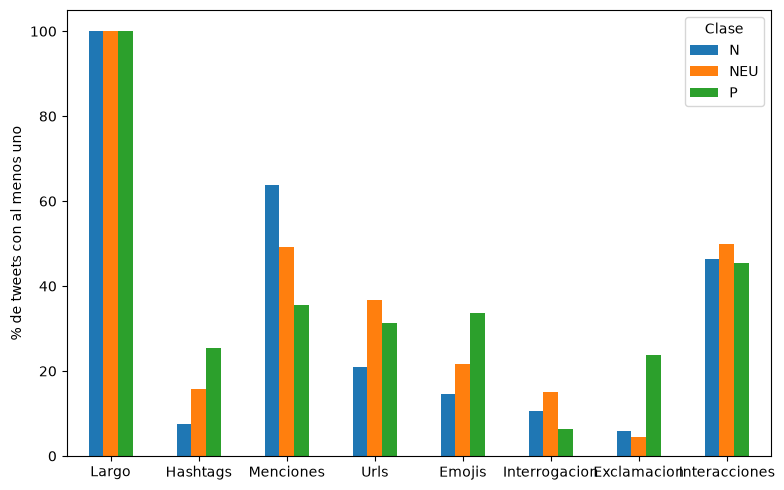

In [16]:
cols = {
    "length": "Largo",
    "hashtag_count": "Hashtags",
    "mention_count": "Menciones",
    "url_count": "Urls",
    "emoji_count": "Emojis",
    "interrogation_count": "Interrogacion",
    "exclamation_count": "Exclamacion",
    "tweet_interactions": "Interacciones"
}

# % de tweets de cada clase que tienen al menos 1 del elemento
pct = (df[list(cols)] > 0).groupby(df["polarity"]).mean() * 100
pct = pct.rename(columns=cols)

ax = pct.T.plot(kind="bar", figsize=(8, 5))
ax.set_ylabel("% de tweets con al menos uno")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

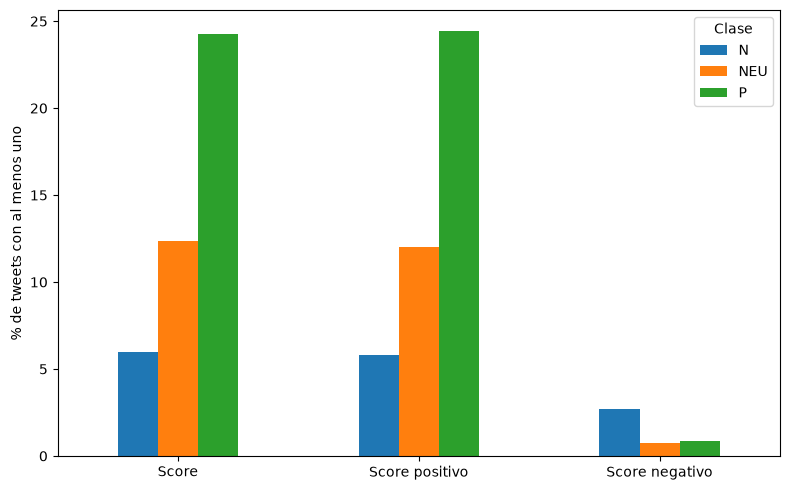

In [17]:
cols = {
    "emoji_score": "Score",
    "emoji_pos": "Score positivo",
    "emoji_neg": "Score negativo"
}

# % de tweets de cada clase que tienen al menos 1 del elemento
pct = (df[list(cols)] > 0).groupby(df["polarity"]).mean() * 100
pct = pct.rename(columns=cols)

ax = pct.T.plot(kind="bar", figsize=(8, 5))
ax.set_ylabel("% de tweets con al menos uno")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

**Qué nos dicen los gráficos**

- **Hashtags y exclamaciones** aparecen mucho más en positivos.
- **Menciones**: ~64% de los negativos son respuestas a alguien, contra ~36% de los positivos. Se puede decir que la gente discute respondiendo.
- **URLs**: más comunes en neutros (~37%), que muchas veces son noticias compartidas.
- **Emojis positivos**: ~24% de los positivos tiene alguno, contra ~6% de los negativos. Los emojis negativos son raros en todas las clases.
- **Largo** e **interacciones**: casi iguales entre clases, así que distinguen poco.

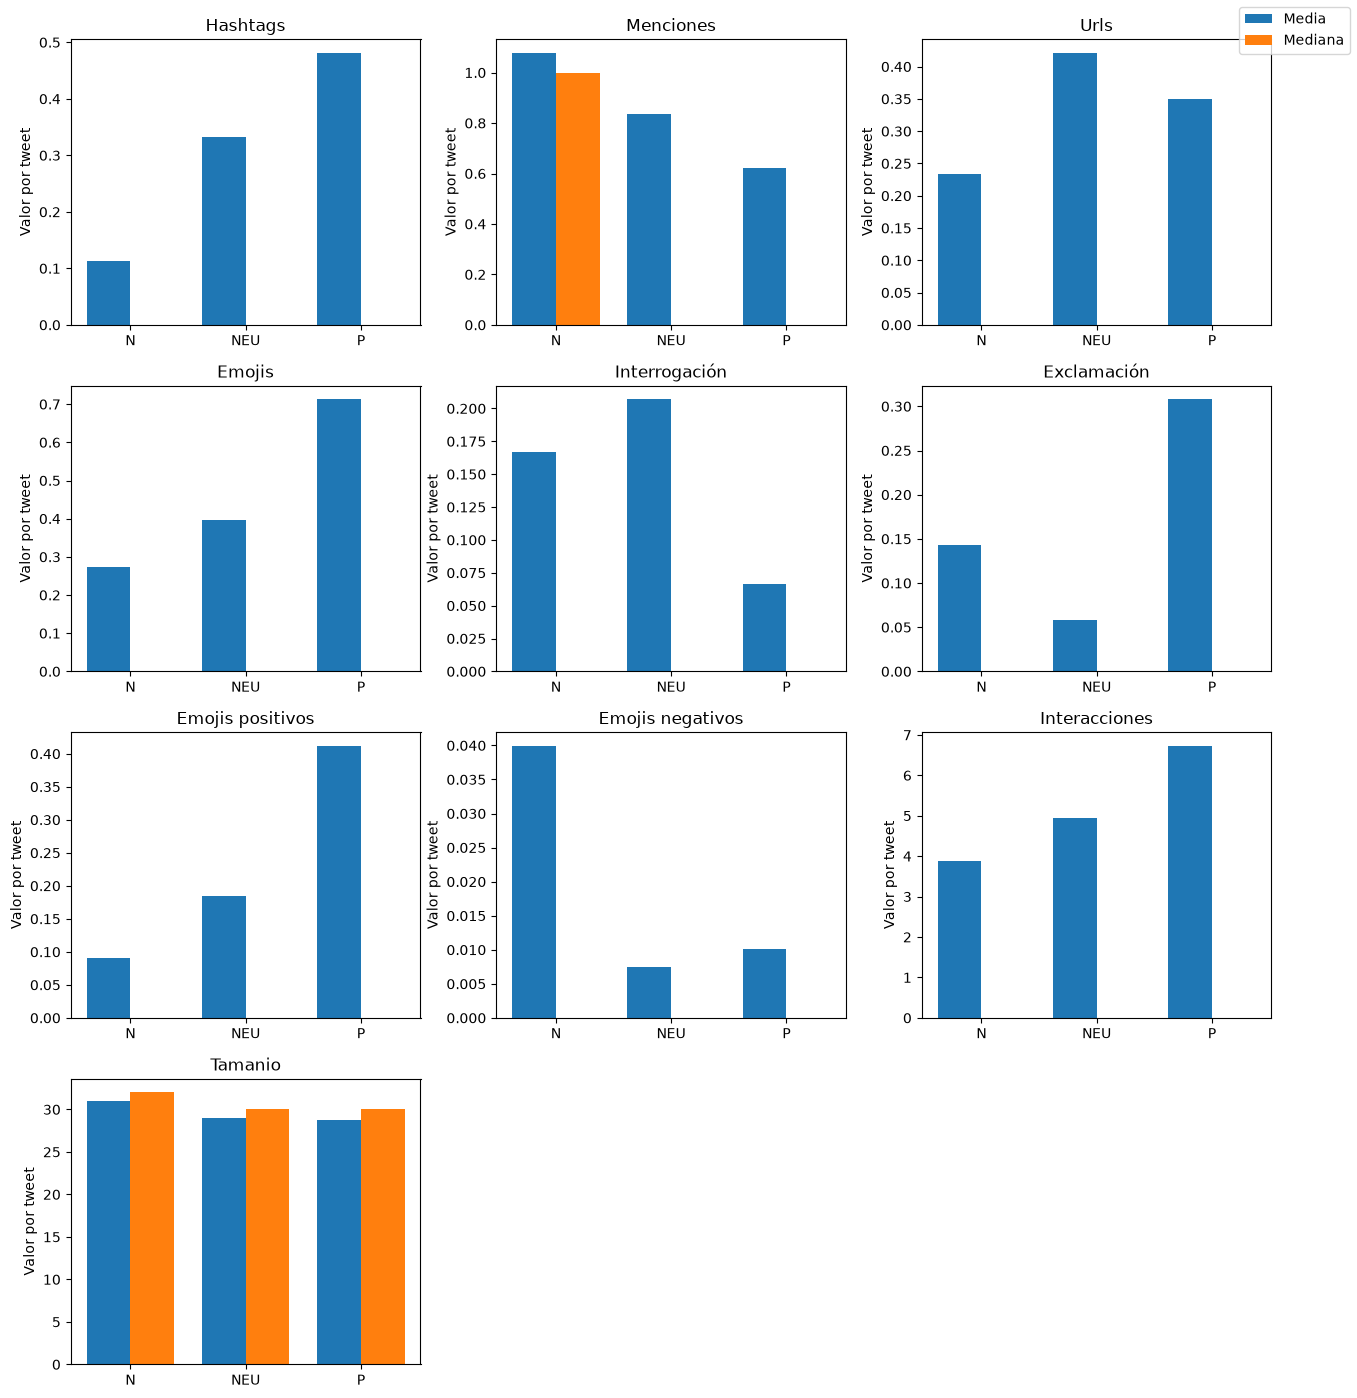

In [18]:
nombres = {
    "hashtag_count": "Hashtags",
    "mention_count": "Menciones",
    "url_count": "Urls",
    "emoji_count": "Emojis",
    "interrogation_count": "Interrogación",
    "exclamation_count": "Exclamación",
    "emoji_pos": "Emojis positivos",
    "emoji_neg": "Emojis negativos",
    "tweet_interactions": "Interacciones",
    "length": "Tamanio"
}

grupos = df.groupby("polarity")[list(nombres)]
medias = grupos.mean()
medianas = grupos.median()

clases = medias.index.tolist()
x = np.arange(len(clases))
ancho = 0.38

n = len(nombres)
ncols = 3
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, titulo) in zip(axes, nombres.items()):
    ax.bar(x - ancho / 2, medias[col], ancho, label="Media", color="tab:blue")
    ax.bar(x + ancho / 2, medianas[col], ancho, label="Mediana", color="tab:orange")
    ax.set_title(titulo)
    ax.set_xticks(x)
    ax.set_xticklabels(clases)
    ax.set_ylabel("Valor por tweet")

for ax in axes[n:]:
    ax.axis("off")

# una sola leyenda para toda la figura
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")

plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.show()

En casi todas las variables la **mediana es 0**. La mayoría de los tweets no tiene hashtags, emojis, etc., y la media se mueve por los pocos que sí tienen. El único caso con mediana distinta de 0 en menciones son los negativos, lo que refuerza que más de la mitad de los negativos son respuestas.

In [19]:
df.columns

Index(['text', 'polarity', 'favorite_count', 'retweet_count',
       'user_followers_count', 'user_friends_count', 'user_favourites_count',
       'user_statuses_count', 'user_verified', 'user_default_profile',
       'tweet_interactions', 'length', 'hashtag_count', 'mention_count',
       'url_count', 'interrogation_count', 'exclamation_count', 'emoji_count',
       'emoji_score', 'emoji_pos', 'emoji_neg'],
      dtype='str')

In [20]:
def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

df = df.drop(columns=["emoji_score", "emoji_count", "tweet_interactions", "mention_count", "user_followers_count", "user_default_profile", "user_verified"])

**Columnas que sacamos antes de modelar**

- `emoji_count` y `emoji_score`: son redundantes con `emoji_pos` / `emoji_neg`.
- `tweet_interactions`: es literalmente `favorite_count + retweet_count`, que ya están como columnas.
- `mention_count`: las menciones ya quedaron en el texto como el token `MENCION`, así que el modelo de texto las ve igual.
- `user_followers_count`, `user_verified`, `user_default_profile`: son datos del usuario, no del tweet. 

In [21]:
X = df.drop(columns=["polarity"])
y = df["polarity"]

# 80% para train/validacion y 20% para test
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#print(len(X_train)/len(df))

**Partición de los datos**

- Separamos un **20% como test** (732 tweets) y no lo tocamos hasta el final. Sirve para tener una estimación honesta de cómo anda el modelo con tweets que nunca vio.
- Con el 80% restante (`X_trval`) elegimos hiperparámetros usando **validación cruzada estratificada** (3 folds) en vez de separar un conjunto de validación fijo. Con un dataset chico, un set de validación fijo desperdicia datos y da resultados que dependen mucho de qué tweets cayeron ahí. Con CV, todos los tweets se usan para entrenar y para validar.
- Usamos 3 folds y no 5 por tiempo: algunos grids tienen cientos de combinaciones y modelos pesados (red neuronal, embeddings).
- `stratify=y` mantiene la proporción de clases en ambas partes, y `random_state=42` hace que el split sea siempre el mismo.

In [22]:
number_columns = ["user_statuses_count", "length",
    "emoji_pos", "user_friends_count", "user_favourites_count", "emoji_neg",
    "favorite_count", "retweet_count", "hashtag_count", "url_count", "exclamation_count", "interrogation_count",
]

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int)

X_trval.head()
y_trval.head()

2412    NEU
1301    NEU
2890    NEU
4002    NEU
2239    NEU
Name: polarity, dtype: str

## Mapeo de texto y Tokenizadores

Los modelos no entienden texto, solo números, así que probamos tres formas:

- **Bag of Words (BoW)**: cuenta cuántas veces aparece cada palabra. Simple, pero no sabe de orden ni de sinónimos ("bueno" y "excelente" son columnas distintas).
- **TF-IDF**: igual que BoW, pero le baja el peso a las palabras que aparecen en todos lados y se lo sube a las que son características de pocos tweets.
- **Embeddings**: un modelo de lenguaje pre-entrenado convierte cada tweet en un vector que representa su *significado*. Tweets parecidos quedan cerca aunque usen palabras distintas.

In [23]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

STOP_WORDS = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        stemmer = SnowballStemmer('spanish')
        clean_X = []
        for text in X:
            text = normalizar_texto(text)

            text = text.lower()

            tokens = word_tokenize(text, language='spanish')

            tokens = [t for t in tokens if t not in STOP_WORDS]


            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [simplemma.lemmatize(t, lang='es')for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X


class LightCleaner(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        clean_X = []
        for text in X:
            text = normalizar_texto(text)
            text = re.sub(r"\s+", " ", text).strip()
            clean_X.append(text)
        return clean_X

**¿Por qué dos limpiadores?**

- **`TextCleaner` (limpieza fuerte)**: pasa a minúsculas, tokeniza, saca stopwords ("el", "de", "que"...) y opcionalmente hace *stemming* o *lematización*. Es para BoW/TF-IDF: ahí cada palabra es una columna, así que conviene achicar el vocabulario y juntar variantes de la misma palabra ("herramienta", "herramientas" → la misma).
  - *Stemming* corta la palabra a su raíz de forma bruta ("herramientas" → "herramient"). Es rápido pero a veces queda feo.
  - *Lematización* lleva la palabra a su forma de diccionario ("buenas" → "bueno"). Es más prolija pero más lenta.
  - No elegimos una a ojo: las probamos las dos en el Grid Search.
- **`LightCleaner` (limpieza mínima)**: solo normaliza. Es para los embeddings, porque esos modelos fueron entrenados con texto natural y **usan el contexto**. Si le sacamos las stopwords, "no me gusta" queda "gusta" y se invierte el sentido. Mejor dejarle la frase entera.

In [24]:
class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    # Alternativas especificas de espanol para comparar:
    #   - hiiamsid/sentence_similarity_spanish_es
    #   - PlanTL-GOB-ES/roberta-base-bne (requiere mean pooling)
    # Cache a nivel de CLASE: sobrevive a los clones que arma GridSearchCV
    # Clave: (nombre_del_modelo, texto) -> vector
    # El modelo es multilingue (incluye espanol) y trae su propio tokenizador.
    _cache = {}

    def __init__(self, model_name='hiiamsid/sentence_similarity_spanish_es'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aqui para evitar errores de serializacion
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Permite usar el transformador aunque se lo llame sin fit previo.
        if not hasattr(self, "model_"):
            self.fit(X)

        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implicitamente el "Mean Pooling"
        # Solo calculamos los textos que aun no estan en la cache
        texts = list(X)
        faltantes = [t for t in texts if (self.model_name, t) not in self._cache]
        if faltantes:
            vectores = self.model_.encode(faltantes, show_progress_bar=False)
            for t, v in zip(faltantes, vectores):
                self._cache[(self.model_name, t)] = v
        return np.array([self._cache[(self.model_name, t)] for t in texts])

embedding = EmbeddingTransformer()

class DenseTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if hasattr(X, "toarray"):
            return X.toarray()
        return X

**Transformador de embeddings**

- Usamos `hiiamsid/sentence_similarity_spanish_es`, un modelo entrenado en español y ajustado para generar embeddings de oraciones completas. 
- Lo armamos como transformador de sklearn (`fit` / `transform`) para poder meterlo adentro de un `Pipeline`.
- **Caché**: calcular embeddings es lo más lento del notebook. Como `GridSearchCV` clona el pipeline para cada combinación y cada fold, sin caché se recalcularían los mismos embeddings cientos de veces. Guardamos cada vector la primera vez y después lo reutilizamos. El caché vive a nivel de clase justamente para que sobreviva a esos clones.

## Preprocesador automatizado

In [25]:
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsOneClassifier


class ColumnSelector(BaseEstimator, TransformerMixin):
    """Selecciona un subconjunto de columnas por nombre (para iterar features en el grid)."""
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X[self.columns]

preprocessor = ColumnTransformer([
    (
        'text',
         Pipeline([
            ("cleaner", LightCleaner()),
            ("embedding", EmbeddingTransformer())
        ]),
         'text'),
    (
        "numeric",
        Pipeline([
            ("select", ColumnSelector(number_columns)), #El grid varia que columnas numericas usan
            ("imputer", SimpleImputer(strategy="median")), #Completa datos faltantes
            ("scaler", StandardScaler())
        ]),
        number_columns
    ),
])

#X_trval = pd.concat([X_train, X_val])
#y_trval = np.concatenate([y_train, y_val])

preprocessor.fit(X_trval)                       # aprende solo de train + val
X_trval_prepro = preprocessor.transform(X_trval)
X_test_prepro = preprocessor.transform(X_test)


20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 850.24it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


**Preprocesador compartido (embeddings + numéricas)**

- El `ColumnTransformer` arma una sola matriz pegando el embedding del texto y las numéricas escaladas.
- **`StandardScaler`**: SVM, regresión logística y redes neuronales son sensibles a la escala. Sin escalar, `user_statuses_count` (miles) le pasaría por encima a `exclamation_count` (0, 1, 2) solo por tener números más grandes.
- **Lo ajustamos una sola vez sobre `X_trval`** y guardamos el resultado (`X_trval_prepro`, `X_test_prepro`). Así la SVM, la red neuronal, la regresión logística y Naive Bayes se comparan exactamente sobre las mismas features, y no recalculamos los embeddings en cada combinación del grid.
- **Trade-off que aceptamos**: como el scaler se ajusta antes de la validación cruzada, la media y el desvío "ven" también los folds de validación. Es una filtración mínima y a cambio el Grid Search se vuelve viable en tiempo. El test sí queda totalmente afuera: el preprocesador se ajusta sin él.

## Seccion Support Vector Machines

In [26]:
pipeline = Pipeline([
    ("classifier", LinearSVC(max_iter=5000))
])

param_grid = [
    {
        "classifier": [
            OneVsRestClassifier(
                SVC(max_iter=-1)
            ),
            OneVsOneClassifier(
                SVC(max_iter=-1)
            )
        ],
        "classifier__estimator__kernel": ["linear", "rbf"],
        "classifier__estimator__C": [0.1, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5],
        "classifier__estimator__gamma": [
            "scale", 1e-4, 1e-3, 1e-2, 0.1
        ],
        "classifier__estimator__class_weight": [
            None, "balanced"
        ],
    },
]


cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_svm = GridSearchCV(
    pipeline, param_grid, cv=cv, scoring="f1_macro",
    n_jobs=-1, return_train_score=True, verbose=3
)

## Seccion Red neuronal

In [27]:
import keras
from keras import layers

def build_model(meta, units=512, n_layers=1, dropout=0.3,
                activation="sigmoid", learning_rate=1e-3, device=None):
    model = keras.Sequential()
    model.add(keras.Input(shape=(meta["n_features_in_"],)))
    for _ in range(n_layers):
        model.add(layers.Dense(units, activation=activation))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(meta["n_classes_"], activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [28]:
from scikeras.wrappers import KerasClassifier

preprocessor_nn = ColumnTransformer([
    # Embeddings: limpieza minima, el modelo multilingue ya entiende espanol.
    ("text", Pipeline([
        ("cleaner", LightCleaner()),
        ("vectorizer", EmbeddingTransformer()),
    ]), "text"),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), number_columns),
])

clf = KerasClassifier(
    model=build_model,
    epochs=5,               # 5 epocas por fold en la busqueda
    batch_size=32,
    verbose=0
)

pipeline_nn = Pipeline([
    ("classifier", clf),
])

param_grid = [{
    "classifier__model__units": [64, 128, 256, 512],
    "classifier__model__n_layers": [2, 3, 4],
    "classifier__model__dropout": [0.3],
    "classifier__epochs": [2, 3, 4],
    "classifier__model__activation": ["relu", "sigmoid", "elu"],
    "classifier__model__learning_rate": [
    1e-1, 1e-2, 1e-3, 1e-4, 1e-5
],
    "classifier__batch_size": [32],
}]

grid_search_nn = GridSearchCV(
    pipeline_nn,
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=1,
    verbose=1,
    return_train_score=True,
    refit=True
)

## Seccion Regresion Logistica

Se prueban dos representaciones del texto con Regresión Logística:

1. **Embeddings + numéricas**: usa el mismo `preprocessor` que SVM y la red neuronal (`X_trval_prepro`), así los tres modelos se comparan sobre las mismas features.
​
2. **BoW / TF-IDF + numéricas**: como la tokenización y la vectorización van dentro del pipeline, se entrena sobre X_trval (el texto todavía sin vectorizar, solo normalizado, más las columnas numéricas). Así, en cada fold de la validación cruzada el vocabulario y los pesos TF-IDF se aprenden solo con los datos de entrenamiento de ese fold, y el Grid Search puede elegir el vectorizador, los n-gramas y si conviene aplicar stemming.

In [29]:
import string
from sklearn.linear_model import LogisticRegression

PUNCT = set(string.punctuation) | set("¿¡«»“”‘’…")
# Palabras que NO se eliminan aunque estén en la lista de stopwords
KEEP = {"no", "ni", "sin", "nunca", "tampoco", "nada", "contra", "muy", "pero", "más", "menos"} #Mejores resultados con KEEP puesto
STOP_WORDS_LR = set(stopwords.words('spanish')) - KEEP


class TextCleanerLR(BaseEstimator, TransformerMixin):
    def __init__(self, method=None, ngram_range=(1, 1), remove_stopwords=True):
        self.method = method
        self.ngram_range = ngram_range
        self.remove_stopwords = remove_stopwords

    def fit(self, X, y=None):
        if self.method not in (None, "stem", "lemma"):
            raise ValueError("method debe ser None, 'stem' o 'lemma'")
        return self

    def _is_valid(self, token):
        if not token.strip() or all(c in PUNCT for c in token):
            return False
        # STOP_WORDS_LR conserva negaciones e intensificadores (KEEP)
        if self.remove_stopwords and token in STOP_WORDS_LR:
            return False
        return True

    def _ngrams(self, tokens):
        n_min, n_max = self.ngram_range
        out = []
        for n in range(n_min, n_max + 1):
            out += ["_".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
        return out

    def transform(self, X):
        X = list(X)

        token_lists = [
            [t for t in nltk.word_tokenize(text.lower(), language="spanish") if self._is_valid(t)]
            for text in X
        ]
        if self.method == "stem":
            stemmer = SnowballStemmer("spanish")
            token_lists = [[stemmer.stem(t) for t in toks] for toks in token_lists]
        elif self.method == "lemma":
            token_lists = [[simplemma.lemmatize(t, lang="es") for t in toks] for toks in token_lists]

        return [" ".join(self._ngrams(toks)) for toks in token_lists]

**Detalles de `TextCleanerLR`**

- Saca puntuación y stopwords, **pero no todas**: la lista `KEEP` conserva negaciones e intensificadores ("no", "nunca", "muy", "pero"...). En sentimiento son clave: "es bueno" y "no es bueno" tienen que quedar distintos. Así se obtuvieron mejores resultados.
- El `method` (None / stem / lemma) se deja como parámetro para que lo elija el Grid Search.
- Valida el parámetro en `fit` para que falle rápido si alguien pasa un valor inválido.

In [30]:
# Vista rapida de la representacion BoW sobre el conjunto de entrenamiento
cleaner_lr = TextCleanerLR("lemma")

vectores = cleaner_lr.transform(X_trval["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()

matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print("Vocabulario:", len(vectorizer_BoW.get_feature_names_out()), "terminos")
print(vectorizer_BoW.get_feature_names_out()[:50])
print("Forma BoW:", matriz_BoW.shape, "| Forma TF-IDF:", matriz_Tfidf.shape)

Vocabulario: 7230 terminos
['00' '000' '003' '03x33' '04' '0991349626' '10' '100' '1000' '10000'
 '100x' '102' '10años' '10k' '10x' '11' '110' '113' '11m' '12' '120' '125'
 '125m' '126' '12h' '13' '130' '139' '14' '140' '14h' '15' '150k' '157'
 '15h' '15ieeessbmi' '15th' '15usd' '16' '16h' '16k' '17' '1797' '17abril'
 '17h' '18' '1897' '18abr' '19' '1916']
Forma BoW: (2928, 7230) | Forma TF-IDF: (2928, 7230)


Este vistazo rápido muestra que el vocabulario tiene **7230 términos** para ~2900 tweets, y muchos son basura para el sentimiento: números, códigos y cosas como `0991349626` o `15ieeessbmi`. Por eso en el grid probamos `min_df` (descartar palabras que aparecen en muy pocos tweets) y `max_features` (quedarse con las N palabras más frecuentes), para recortar ese ruido.

In [31]:
# --- Variante 1: Embeddings + numericas (mismas features que SVM y red neuronal) ---
pipeline_lr = Pipeline([
    ("classifier", LogisticRegression(max_iter=3000, random_state=42))
])

param_grid_lr = {
    "classifier__C": [1e-4, 3e-4, 1e-3, 3e-3, 0.01, 0.03, 0.07, 0.1, 0.3, 1, 3],
    "classifier__class_weight": [None, "balanced"],
}

cv_lr = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_lr = GridSearchCV(
    pipeline_lr, param_grid_lr, cv=cv_lr, scoring="f1_macro",
    n_jobs=-1, return_train_score=True, verbose=1
)

# --- Variante 2: BoW / TF-IDF + numericas (se entrena sobre el texto crudo) ---
preprocessor_bow = ColumnTransformer([
    ("text", Pipeline([
        ("cleaner", TextCleanerLR()),
        ("vectorizer", TfidfVectorizer()),
    ]), "text"),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), number_columns),
])

pipeline_lr_bow = Pipeline([
    ("preprocessor", preprocessor_bow),
    ("classifier", LogisticRegression(max_iter=3000, random_state=42)),
])

param_grid_lr_bow = [
    {
        "preprocessor__text__cleaner__method": [None, "stem"],
        "preprocessor__text__vectorizer": [TfidfVectorizer(sublinear_tf=True)],
        "preprocessor__text__vectorizer__ngram_range": [(1, 1), (1, 2)],
        "preprocessor__text__vectorizer__min_df": [2, 3],
        "preprocessor__text__vectorizer__max_features": [3000, 5000],
        "classifier__C": [1.0, 3.0],
        "classifier__class_weight": [None, "balanced"],
    },
    {
        "preprocessor__text__cleaner__method": [None, "stem"],
        "preprocessor__text__vectorizer": [CountVectorizer()],
        "preprocessor__text__vectorizer__ngram_range": [(1, 1), (1, 2)],
        "classifier__C": [0.5, 1.0],
        "classifier__class_weight": [None, "balanced"],
    },
]

grid_search_lr_bow = GridSearchCV(
    pipeline_lr_bow, param_grid_lr_bow, cv=cv_lr, scoring="f1_macro",
    n_jobs=1, return_train_score=True, verbose=1
)

- **`C`** controla la regularización: C chico = modelo más simple (más regularizado), C grande = más libertad para ajustarse a los datos de train. Lo exploramos en escala logarítmica (1e-4 a 3) porque su efecto es multiplicativo.
- **`class_weight`**: `None` vs `"balanced"`, por el desbalance de clases.
- `sublinear_tf=True` usa `1 + log(tf)` en vez de la frecuencia cruda, así repetir una palabra 5 veces no pesa 5 veces más.

## Sección Naive Bayes

En esta sección se explora el algoritmo **Gaussian Naive Bayes (GaussianNB)** para la clasificación del sentimiento en los tweets. Dado que Naive Bayes asume una distribución gaussiana continuada sobre las features e independencia condicional entre ellas, se diseñaron dos estrategias contrastantes para la representación del texto:

1. **Variante 1: Embeddings + PCA + Variables Numéricas**
   Los embeddings generan vectores de alta dimensión densos y fuertemente correlacionados entre sí. Dado que GaussianNB es sensible a la multicolinealidad (asume independencia), aplicar reducción de dimensionalidad mediante Análisis de Componentes Principales (PCA) resulta fundamental. PCA proyecta las variables sobre ejes ortogonales decorrelacionados, haciendo que los vectores densos respeten mejor el supuesto intrínseco del clasificador de Bayes. Se optimiza el número de componentes (`n_components`) dentro del Grid Search.

2. **Variante 2: Bag of Words (BoW) / TF-IDF**
   En lugar de usar la matriz dispersa por defecto que suele combinarse con MultinomialNB, se evalúa GaussianNB transformando la matriz TF-IDF a formato denso. Con el fin de no sobredimensionar la matriz densa en memoria ni saturar la estimación de medias y varianzas gaussianas, se acota agresivamente el tamaño del vocabulario mediante `max_features` (300 a 1000 términos).

**Optimización de Hiperparámetros (`var_smoothing`):**
   GaussianNB no posee un parámetro tradicional de regularización o profundidad. Su hiperparámetro principal es `var_smoothing`, el cual suma una porción de la varianza más grande de todas las características a las varianzas calculadas. Esto actúa como un suavizado para evitar problemas de varianza nula o divisiones por cero en características con muy poca variación en el dataset.

In [32]:
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA

# -------------------------------------------------------------------------
# 1. Variante Embeddings + PCA
# -------------------------------------------------------------------------
# Se aplica PCA previo a GaussianNB para reducir la colinealidad del vector denso.

pipeline_nb_emb = Pipeline([
    ("pca", PCA()),
    ("classifier", GaussianNB())
])

# Rango de hiperparámetros a explorar:
# - n_components: se evalúan distintos grados de compresión (15 a 100 componentes).
# - var_smoothing: escala logarítmica (1e-9 a 1e-2) para ajustar la estabilidad del cálculo gaussiano.

param_grid_nb_emb = {
    "pca__n_components": [15, 30, 50, 75, 100],
    "pca__whiten": [False],
    "classifier__var_smoothing": np.logspace(-9, -2, 8)
}

cv_nb = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_nb_emb = GridSearchCV(
    pipeline_nb_emb, param_grid_nb_emb, cv=cv_nb, scoring="f1_macro",
    n_jobs=-1, return_train_score=True, verbose=1
)

# -------------------------------------------------------------------------
# 2. Variante BoW / TF-IDF
# -------------------------------------------------------------------------
# Pipeline: aplica limpieza liviana, vectorización sublineal TF-IDF, conversión a matriz densa (requerida por GaussianNB) y el clasificador.

pipeline_nb_bow = Pipeline([
    ("cleaner", LightCleaner()),
    ("vectorizer", TfidfVectorizer(sublinear_tf=True)),
    ("to_dense", DenseTransformer()),
    ("classifier", GaussianNB())
])

# Rango de hiperparámetros a explorar:
# - ngram_range: unigramas vs bigramas para capturar expresiones cortas.
# - max_features: acotación del vocabulario para mantener la factibilidad computacional del ajuste gaussiano denso.

param_grid_nb_bow = {
    "vectorizer__ngram_range": [(1, 1), (1, 2)],
    "vectorizer__max_features": [300, 500, 1000],
    "classifier__var_smoothing": np.logspace(-9, -2, 8)
}

grid_search_nb_bow = GridSearchCV(
    pipeline_nb_bow, param_grid_nb_bow, cv=cv_nb, scoring="f1_macro",
    n_jobs=1, return_train_score=True, verbose=1
)

## Seccion Decision Tree

En esta seccion se deja documentado el grid search que se realizo para encontrar el mejor modelo de decision tree, utilizando como preprocesamiento las tecnias de TfIdf, BoW y Embedding.

In [33]:
class TextCleanerDt(BaseEstimator, TransformerMixin):
    def __init__(self, method=None, ngram_range=(1, 1), remove_stopwords=True):
        self.method = method
        self.ngram_range = ngram_range
        self.remove_stopwords = remove_stopwords

    def fit(self, X, y=None):
        if self.method not in (None, "stem", "lemma"):
            raise ValueError("method debe ser None, 'stem' o 'lemma'")
        return self

    def _is_valid(self, token):
        if not token.strip() or all(c in PUNCT for c in token):
            return False
        if self.remove_stopwords and token in STOP_WORDS:
            return False
        return True

    def _ngrams(self, tokens):
        n_min, n_max = self.ngram_range
        out = []
        for n in range(n_min, n_max + 1):
            out += ["_".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
        return out

    def transform(self, X):
        X = list(X)

        if self.method == "lemma":
            import spacy
            nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
            token_lists = []
            for doc in nlp.pipe(X):
                # se filtra por el texto original y después se toma el lema
                token_lists.append([t.lemma_.lower() for t in doc if self._is_valid(t.text.lower())])
        else:
            token_lists = [
                [t for t in nltk.word_tokenize(text.lower(), language="spanish") if self._is_valid(t)]
                for text in X
            ]
            if self.method == "stem":
                stemmer = SnowballStemmer("spanish")
                token_lists = [[stemmer.stem(t) for t in toks] for toks in token_lists]

        return [" ".join(self._ngrams(toks)) for toks in token_lists]

In [34]:
from sklearn.tree import DecisionTreeClassifier

text_col = "text"

text_bow = Pipeline([
    ("cleaner", TextCleanerDt("lemma")),
    ("vectorizer", CountVectorizer()),
])
text_tfidf = Pipeline([
    ("cleaner", TextCleanerDt("lemma")),
    ("vectorizer", TfidfVectorizer()),
])
text_emb = EmbeddingTransformer()

preprocesador = ColumnTransformer([
    ("text", text_bow, text_col),
    ("num", StandardScaler(), number_columns),
])

pipeline = Pipeline([
    ("pre", preprocesador),
    ("classifier", DecisionTreeClassifier(random_state=42)),
], memory="cache_dir")

param_grid_dt = [
    {
        "pre__text": [text_bow, text_tfidf],
        "pre__text__cleaner__method": ["stem", "lemma"],
        "pre__text__cleaner__ngram_range": [(1,1), (1, 2)],
        "classifier__max_depth": [5, 10, 20],
        "classifier__min_samples_leaf": [1, 5, 10],
        "classifier__min_samples_split": [2, 5, 10],
        'classifier__class_weight': ["balanced"],
    },
    {
        "pre__text": [text_emb],
        "classifier__max_depth": [5, 10, 20],
        "classifier__min_samples_leaf": [1, 5, 10, 20],
        'classifier__class_weight': ["balanced"],
    },
]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search_dt = GridSearchCV(pipeline, param_grid_dt, cv=skf, scoring="f1_macro", n_jobs=1, verbose=1)
grid_search_dt.fit(X_trval, y_trval)
print(grid_search_dt.best_score_)
print(grid_search_dt.best_params_)

Fitting 3 folds for each of 228 candidates, totalling 684 fits


20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1010.33it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199

0.500388341628217
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'pre__text': EmbeddingTransformer()}


## Comparacion de modelos de Decision Tree

En esta seccion, se entrenaron 3 modelos diferentes de decision tree para ver si habia una mejora en los resultados al convertir el problema de clasificacion multiclase a uno de clasificacion binaria: decision tree, One versus One y One versus All. Para las estrategias de One versus One y One versus All se utilizo como algoritmos, al mejor resultante del grid search previo.

In [35]:
pipeline_dt = grid_search_dt.best_estimator_
preprocesador_dt = pipeline_dt.named_steps["pre"]
mejor_modelo_dt = pipeline_dt.named_steps["classifier"]

In [36]:
from sklearn import clone

modelo_ovo_dt = Pipeline([
    ("pre", clone(preprocesador_dt)),
    ("classifier", OneVsOneClassifier(
        clone(mejor_modelo_dt)
    ))
])

modelo_ovo_dt.fit(X_trval, y_trval);

20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 523.62it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


In [37]:
modelo_ova_dt = Pipeline([
    ("pre", clone(preprocesador_dt)),
    ("classifier", OneVsRestClassifier(
        clone(mejor_modelo_dt)
    ))
])

modelo_ova_dt.fit(X_trval, y_trval);

20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 522.25it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


## Eleccion de modelo

Finalmente, al comparar la metrica F1 entre los 3 modelos, se concluyo que el mejor fue el Decision Tree comun.

In [38]:
from sklearn.model_selection import cross_val_score

for nombre, m in [("DT", pipeline_dt), ("OvO", modelo_ovo_dt), ("OvR", modelo_ova_dt)]:
    print(nombre, cross_val_score(m, X_trval, y_trval, cv=skf, scoring="f1_macro").mean())

20988 | INFO | No device provided, using cpu


DT 0.500388341628217


20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 869.17it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 951.84it/s]
20988 | INFO | HTTP

OvO 0.48896798358965105


20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1052.83it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 905.47it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?

OvR 0.4611334795264121


## Seccion Random Forest

Después del Decision Tree probamos Random Forest, que entrena muchos árboles, cada uno con una muestra al azar de los tweets y mirando solo algunas columnas en cada división, y después promedia lo que dicen. Un árbol solo es muy inestable: cambiás unos pocos datos y cambia todo. El promedio de muchos árboles distintos es mucho más estable y sobreajusta menos.

Reutilizamos el `preprocesador` de la sección de Decision Tree (limpieza con `TextCleanerDt` + BoW o TF-IDF + numéricas escaladas). El preprocesamiento va **adentro del pipeline**, así cada fold de la validación cruzada arma su vocabulario sin ver los datos de validación de ese fold.

In [39]:
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline([
    ("pre", preprocesador),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid_rf = [
    {
        "pre__text": [text_bow, text_tfidf],
        "pre__text__cleaner__method": ["stem"],
        "pre__text__cleaner__ngram_range": [(1,1), (1, 2)],
        "classifier__criterion": ["gini", "entropy"],
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [2, 5],
        "classifier__max_features": ["sqrt", "log2"],
        "classifier__class_weight": ["balanced"]
    },{
        "pre__text": [text_emb],
        "classifier__criterion": ["gini", "entropy"],
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [2, 5],
        "classifier__max_features": ["sqrt", "log2"],
        "classifier__class_weight": ["balanced"]
    }
]

cv_rf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=cv_rf, scoring="f1_macro", n_jobs=-1, return_train_score=True, verbose=1)

**Hiperparámetros del grid de Random Forest**

- **`n_estimators`** (cantidad de árboles): más árboles = predicción más estable, pero más lenta. A partir de cierto punto ya no mejora (lo vemos en la curva de complejidad).
- **`max_depth`, `min_samples_split`, `min_samples_leaf`**: limitan cuánto puede crecer cada árbol. Un árbol sin límites memoriza el train (overfitting), y estos parámetros lo frenan.
- **`max_features`** (`sqrt` / `log2`): cada división del árbol mira solo un subconjunto al azar de columnas. Esto hace que los árboles sean distintos entre sí, que es justamente lo que hace funcionar al bosque: si todos los árboles fueran iguales, promediarlos no serviría de nada.
- **`criterion`**: gini vs entropy, dos formas de medir qué tan "pura" queda una división. Suelen dar parecido, pero es barato probar las dos.
- **`class_weight="balanced"` fijo**: en el Decision Tree ya habíamos visto que sin balancear los árboles tienden a predecir siempre `NEU`.

## Definicion de funciones evaluativas

In [40]:
def graficar_complejidad(estimador, nombre, param_name,
                         param_range=None, X=None, y=None, cv=3,
                         scoring="f1_macro",
                         xlabel=None, log_x=True, figsize=(9, 5), grid=None):
    """Dibuja la curva de complejidad (curva de validación) de un modelo.

    Parámetros
    ----------
    estimador : GridSearchCV o estimador ya entrenado
        Si es un GridSearchCV se usa su ``best_estimator_`` y sus
        ``cv_results_`` para inferir los valores probados del parámetro.
    nombre : nombre del modelo para el título
    param_name : str
        Nombre completo del parámetro dentro del pipeline
        (ej. ``"classifier__model__learning_rate"``).
    param_range : iterable, opcional
        Valores a probar. Si es ``None`` se toman del Grid Search.
    X, y : datos de entrenamiento/validación
        Por defecto usa ``X_trval_prepro`` e ``y_trval``.
    cv : int o validador cruzado
    scoring : métrica a optimizar
    xlabel : etiqueta del eje X (por defecto, el nombre del parámetro)
    log_x : bool
        Usa escala logarítmica en X (útil para learning rate).
    figsize : tamaño de la figura
    grid : GridSearchCV, opcional
        Búsqueda de la que se toman los valores del parámetro cuando
        ``estimador`` es un modelo ya entrenado.
    """
    if X is None:
        X = X_trval_prepro
    if y is None:
        y = y_trval

    # Acepta tanto un GridSearchCV como un modelo ya entrenado
    if hasattr(estimador, "best_estimator_"):
        pipe = estimador.best_estimator_
        if grid is None:
            grid = estimador
    else:
        pipe = estimador

    # Valores del parámetro probados en el Grid Search
    if param_range is None:
        if grid is None or not hasattr(grid, "cv_results_"):
            raise ValueError(
                "Pasá 'param_range' o un GridSearchCV entrenado en 'grid' "
                "para inferir los valores del parámetro."
            )
        resultados = pd.DataFrame(grid.cv_results_)
        columna = f"param_{param_name}"
        if columna not in resultados:
            raise ValueError(f"El Grid Search no probó el parámetro '{param_name}'")
        valores = resultados[columna].dropna().unique()
        try:
            valores = sorted(valores.astype(float))
        except (TypeError, ValueError):
            valores = list(valores)
        param_range = valores

    param_range = list(param_range)
    if len(param_range) < 2:
        raise ValueError(f"Se necesitan al menos 2 valores para '{param_name}'")

    display = ValidationCurveDisplay.from_estimator(
        pipe,
        X,
        y,
        param_name=param_name,
        param_range=param_range,
        scoring=scoring,
        cv=cv,
        n_jobs=1,
        error_score="raise",
        std_display_style="errorbar",
        errorbar_kw={"marker": "o", "capsize": 3},
    )

    display.ax_.set_title(f"Curva de complejidad - {nombre}")
    display.ax_.set_xlabel(xlabel or param_name)
    display.ax_.set_ylabel("F1 macro" if scoring == "f1_macro" else scoring.replace("_", " ").upper())
    if log_x:
        display.ax_.set_xscale("log")
    display.ax_.legend(["Entrenamiento", "Validación cruzada"])
    display.ax_.grid(True)
    display.figure_.set_size_inches(*figsize)
    display.figure_.tight_layout()
    plt.show()

    return display


**Curva de complejidad (`graficar_complejidad`)**

Toma el mejor modelo del grid y le va variando **un solo** hiperparámetro, midiendo el F1 macro en train y en validación cruzada. Sirve para ver si el valor elegido tiene sentido:
- Si train y validación son bajos los dos → el modelo es demasiado simple (**underfitting**).
- Si train es muy alto pero validación baja → está memorizando (**overfitting**).
- El punto bueno es donde la curva de validación llega a su máximo.

Por defecto toma los valores del parámetro que se probaron en el grid, aunque se le puede pasar un rango más amplio para ver la curva completa.

In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score


def evaluar_modelo(pipe, nombre="Test", X=None, y=None):
    """Evalúa cualquier clasificador entrenado y muestra métricas y gráficos.

    Admite modelos con ``predict_proba`` (red neuronal, regresión logística,
    etc.) y modelos que solo tienen ``decision_function`` (SVM, LinearSVC,
    OneVsOneClassifier, etc.).

    Parámetros
    ----------
    pipe : estimador o GridSearchCV entrenado
    nombre : nombre del conjunto para los títulos
    X, y : datos a evaluar. Por defecto usa ``X_test_prepro`` e ``y_test``.
    """
    if X is None:
        X = X_test_prepro
    if y is None:
        y = y_test

    # Si es un GridSearchCV, usamos el mejor modelo encontrado
    modelo = pipe.best_estimator_ if hasattr(pipe, "best_estimator_") else pipe

    clases = list(getattr(modelo, "classes_", np.unique(y)))
    y_pred = modelo.predict(X)

    # Puntajes para las curvas ROC
    if hasattr(modelo, "predict_proba"):
        y_score = modelo.predict_proba(X)
        origen_score = "predict_proba"
    elif hasattr(modelo, "decision_function"):
        y_score = np.asarray(modelo.decision_function(X))
        origen_score = "decision_function"
        # En binario decision_function devuelve una sola columna
        if y_score.ndim == 1:
            y_score = np.column_stack([-y_score, y_score])
        elif y_score.shape[1] == 1:
            y_score = np.column_stack([-y_score[:, 0], y_score[:, 0]])
    else:
        y_score = None
        origen_score = None

    # ---------- Métricas ----------
    acc = accuracy_score(y, y_pred)
    prec_macro = precision_score(y, y_pred, average="macro", zero_division=0)
    prec_weighted = precision_score(y, y_pred, average="weighted", zero_division=0)
    rec_macro = recall_score(y, y_pred, average="macro", zero_division=0)
    f1_macro = f1_score(y, y_pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y, y_pred, average="weighted", zero_division=0)

    print(f"===== {nombre} =====")
    print(f"Accuracy:            {acc:.4f}")
    print(f"Precision (macro):   {prec_macro:.4f}")
    print(f"Precision (weighted):{prec_weighted:.4f}")
    print(f"Recall (macro):      {rec_macro:.4f}")
    print(f"F1 (macro):          {f1_macro:.4f}")
    print(f"F1 (weighted):       {f1_weighted:.4f}")

    if y_score is not None:
        y_bin = label_binarize(y, classes=clases)
        if y_bin.shape[1] == 1: # binario
            y_bin = np.column_stack([1 - y_bin[:, 0], y_bin[:, 0]])
        auc_por_clase = [
            roc_auc_score(y_bin[:, i], y_score[:, i])
            for i in range(len(clases))
        ]
        roc_auc = float(np.mean(auc_por_clase))
        print(f"ROC-AUC (OvR macro): {roc_auc:.4f}   (usando {origen_score})")
    else:
        auc_por_clase = None
        roc_auc = None
        print("ROC-AUC: no disponible (el modelo no tiene predict_proba ni decision_function)")

    print("\nReporte por clase:\n")
    print(classification_report(y, y_pred, labels=clases, zero_division=0))

    # ---------- Gráficos ----------
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    cm = confusion_matrix(y, y_pred, labels=clases)
    ConfusionMatrixDisplay(cm, display_labels=clases).plot(
        ax=ax[0], cmap="Blues", colorbar=False
    )
    ax[0].set_title(f"Matriz de confusión - {nombre}")

    cm_norm = confusion_matrix(y, y_pred, labels=clases, normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(
        ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f"
    )
    ax[1].set_title("Matriz de confusión normalizada")

    if y_score is not None:
        for i, clase in enumerate(clases):
            fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
            ax[2].plot(fpr, tpr, label=f"{clase} (AUC = {auc_por_clase[i]:.3f})")
        ax[2].plot([0, 1], [0, 1], "k--", label="Azar")
        ax[2].set_xlabel("Tasa de falsos positivos")
        ax[2].set_ylabel("Tasa de verdaderos positivos")
        ax[2].set_title("Curvas ROC (One-vs-Rest)")
        ax[2].legend(loc="lower right")
    else:
        ax[2].text(0.5, 0.5, "ROC no disponible", ha="center", va="center")
        ax[2].set_axis_off()

    plt.tight_layout()
    plt.show()

    return {
        "accuracy": acc,
        "precision_macro": prec_macro,
        "precision_weighted": prec_weighted,
        "recall_macro": rec_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "roc_auc": roc_auc,
        "y_pred": y_pred,
        "y_score": y_score,
    }

**Evaluación en test (`evaluar_modelo`)**

Una sola función para evaluar todos los modelos de la misma manera, así la comparación es justa. Muestra:
- **Accuracy, precision, recall y F1**, en versión *macro* (todas las clases pesan igual, que es la que nos importa por el desbalance) y *weighted* (ponderada por la cantidad de tweets de cada clase, como referencia).
- **Reporte por clase**: para ver *en qué* clase falla el modelo, que un solo número esconde.
- **Matriz de confusión** (normal y normalizada por fila): la normalizada muestra el recall de cada clase sin que la clase grande tape a las chicas.
- **ROC-AUC One-vs-Rest**: mide qué tan bien el modelo *ordena* los tweets por probabilidad, independientemente del umbral. Para modelos sin `predict_proba` (como la SVM) usa `decision_function`.

In [42]:
def predecir_tweets(modelo, tweets, preprocessor=None, number_columns=None,
                    medianas=None, nombre="Predicción"):
    """Predice la polaridad de una lista de tweets con cualquier modelo entrenado.

    La función arma las features de entrada (texto + columnas numéricas
    completadas con la mediana) y aplica el preprocesador. No calibra el
    modelo: si se necesitan probabilidades, quien llama debe pasar un modelo
    ya calibrado (por ejemplo, con ``CalibratedClassifierCV``).

    Parámetros
    ----------
    modelo : estimador o pipeline entrenado
        Debe esperar datos ya preprocesados.
    tweets : list[str]
        Textos a clasificar.
    preprocessor : ColumnTransformer, opcional
        Por defecto usa el ``preprocessor`` del notebook.
    number_columns : list[str], opcional
        Columnas numéricas que completa la función. Por defecto usa
        ``number_columns`` del notebook.
    medianas : pd.Series, opcional
        Valores para completar las columnas numéricas. Por defecto usa
        la mediana de ``X_trval``.
    nombre : str
        Título que se imprime antes de la tabla.
    """
    if preprocessor is None:
        preprocessor = globals()["preprocessor"]
    if number_columns is None:
        number_columns = globals()["number_columns"]
    if medianas is None:
        medianas = X_trval[number_columns].median()

    # Armamos la entrada con el texto y valores numéricos neutros
    entrada = pd.DataFrame({"text": tweets})
    for col in number_columns:
        entrada[col] = medianas[col]

    X_entrada = preprocessor.transform(entrada)

    # Si es un GridSearchCV, usamos el mejor modelo encontrado
    modelo_eval = modelo.best_estimator_ if hasattr(modelo, "best_estimator_") else modelo
    y_pred = modelo_eval.predict(X_entrada)

    print(f"===== {nombre} =====")

    if hasattr(modelo_eval, "predict_proba"):
        scores = modelo_eval.predict_proba(X_entrada)
        clases = list(getattr(modelo_eval, "classes_", range(scores.shape[1])))
        resultado = pd.DataFrame(scores, columns=clases).round(4)
    elif hasattr(modelo_eval, "decision_function"):
        scores = np.asarray(modelo_eval.decision_function(X_entrada))
        clases = list(getattr(modelo_eval, "classes_", range(1 if scores.ndim == 1 else scores.shape[1])))
        if scores.ndim == 1:
            nombre_score = f"score_{clases[1]}" if len(clases) > 1 else "score"
            resultado = pd.DataFrame({nombre_score: scores}).round(4)
        else:
            resultado = pd.DataFrame(
                scores,
                columns=[f"score_{clase}" for clase in clases],
            ).round(4)
        print("(el modelo no tiene predict_proba; se muestran scores de decisión)")
    else:
        resultado = pd.DataFrame()
        print("(el modelo no tiene predict_proba ni decision_function; solo se muestran predicciones)")

    resultado.insert(0, "tweet", tweets)
    resultado.insert(1, "prediccion", y_pred)
    print(resultado.to_string(index=False))

    return resultado


**Predicción de tweets nuevos (`predecir_tweets`)**

Para probar los modelos con frases inventadas por nosotros. El problema es que un tweet nuevo es solo texto: no tiene likes, retweets, ni datos del usuario. Para esas columnas usamos la **mediana de train**, que es un valor "típico" y neutro, así la predicción depende casi solo del texto.

## Seccion de resultados grid_search

In [43]:
grid_search_nn.fit(X_trval_prepro, y_trval)

print("="*30)
print("Mejores parametros red neuronal:", grid_search_nn.best_params_)
print("Mejor score (CV):", grid_search_nn.best_score_)
print("="*30)
best_model_nn = grid_search_nn.best_estimator_

grid_search_svm.fit(X_trval_prepro, y_trval)
print("="*30)
print("Mejores parametros svm:", grid_search_svm.best_params_)
print("Mejor score (CV):", grid_search_svm.best_score_)
print("="*30)
best_model_svm = grid_search_svm.best_estimator_

Fitting 3 folds for each of 540 candidates, totalling 1620 fits
Mejores parametros red neuronal: {'classifier__batch_size': 32, 'classifier__epochs': 4, 'classifier__model__activation': 'sigmoid', 'classifier__model__dropout': 0.3, 'classifier__model__learning_rate': 0.001, 'classifier__model__n_layers': 4, 'classifier__model__units': 512}
Mejor score (CV): 0.6799109668847959
Fitting 3 folds for each of 440 candidates, totalling 1320 fits
Mejores parametros svm: {'classifier': OneVsRestClassifier(estimator=SVC()), 'classifier__estimator__C': 2, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'scale', 'classifier__estimator__kernel': 'rbf'}
Mejor score (CV): 0.6976848708065991


===== Red neuronal - Test =====
Accuracy:            0.7514
Precision (macro):   0.6864
Precision (weighted):0.7609
Recall (macro):      0.7192
F1 (macro):          0.7001
F1 (weighted):       0.7546
ROC-AUC (OvR macro): 0.8813   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.58      0.72      0.64       110
         NEU       0.84      0.79      0.81       484
           P       0.64      0.65      0.65       138

    accuracy                           0.75       732
   macro avg       0.69      0.72      0.70       732
weighted avg       0.76      0.75      0.75       732



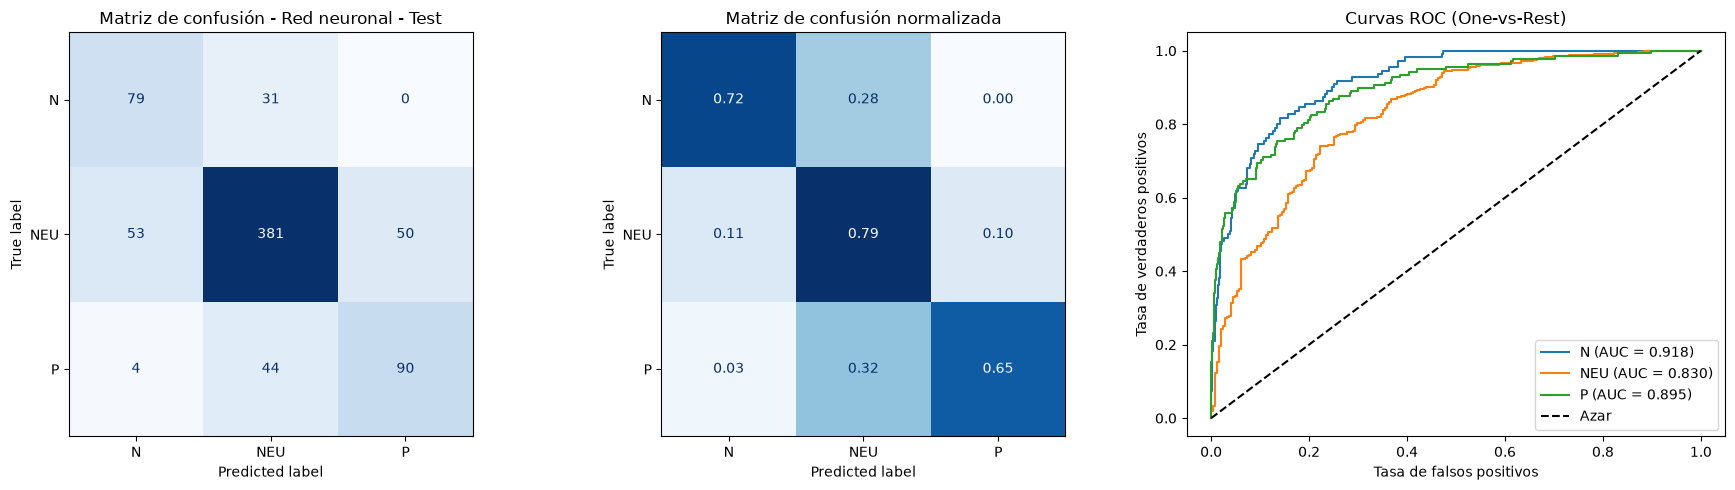

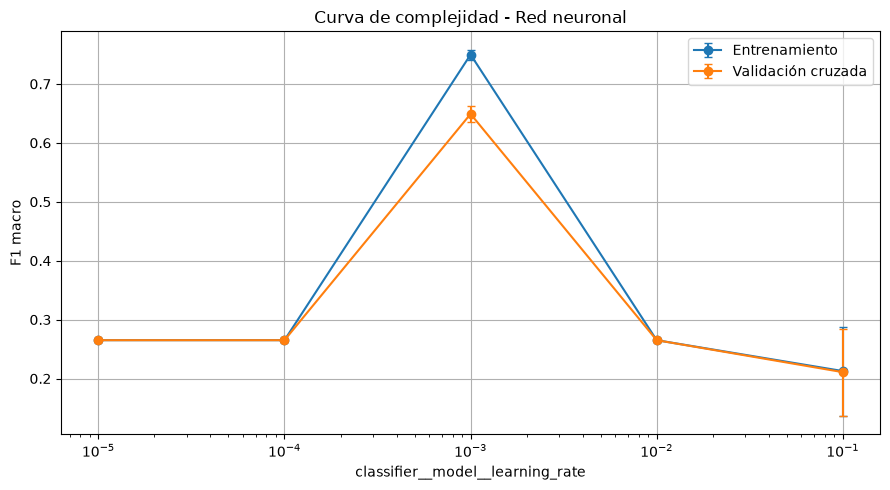

In [44]:
evaluar_modelo(best_model_nn, nombre="Red neuronal - Test")
graficar_complejidad(grid_search_nn, nombre="Red neuronal", param_name="classifier__model__learning_rate")

===== SVM - Test =====
Accuracy:            0.7486
Precision (macro):   0.6821
Precision (weighted):0.7503
Recall (macro):      0.6879
F1 (macro):          0.6846
F1 (weighted):       0.7493
ROC-AUC (OvR macro): 0.8738   (usando decision_function)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.60      0.58      0.59       110
         NEU       0.82      0.81      0.81       484
           P       0.63      0.67      0.65       138

    accuracy                           0.75       732
   macro avg       0.68      0.69      0.68       732
weighted avg       0.75      0.75      0.75       732



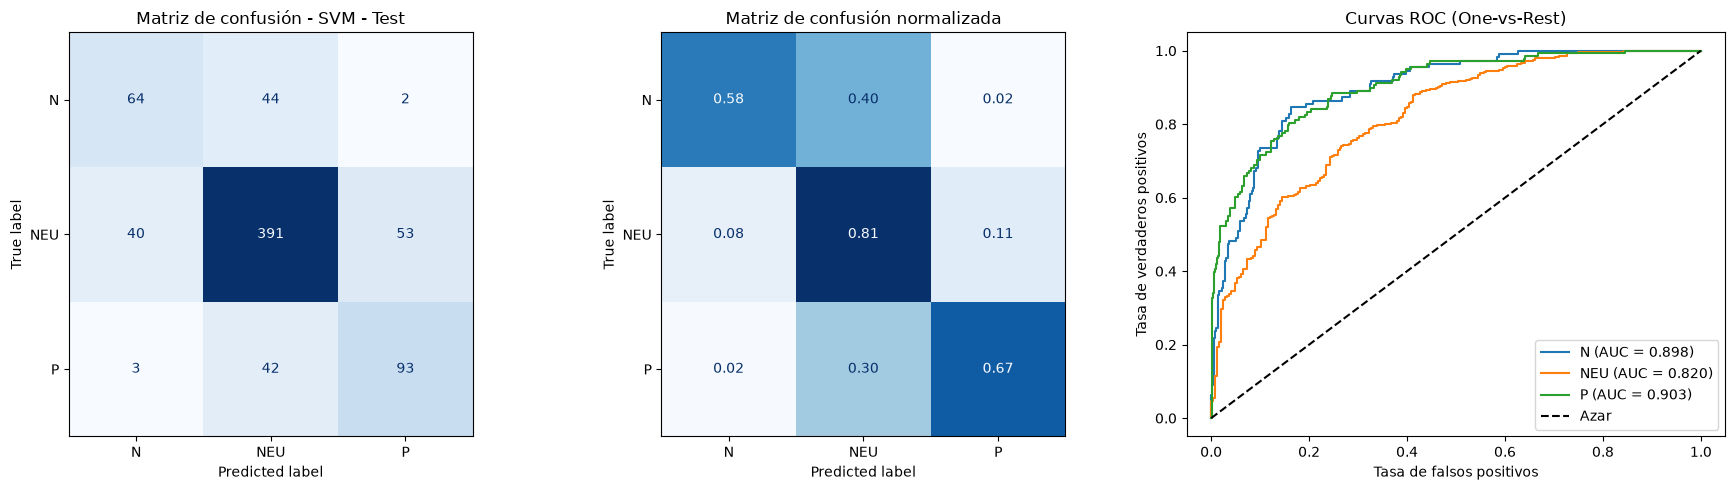

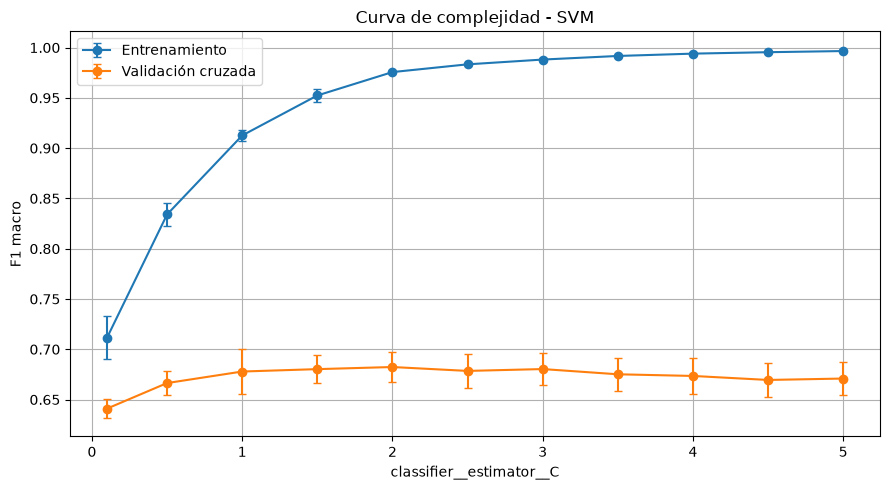

In [45]:
evaluar_modelo(best_model_svm, nombre="SVM - Test")
graficar_complejidad(best_model_svm,nombre="SVM",param_name="classifier__estimator__C",grid=grid_search_svm,log_x=False)

In [46]:
tweets = [
    "A veces funciona, a veces no",
    "Nos puede llegar a sacar el trabajo, es un peligro",
    "Es una buena herramienta",
    "Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre"
]

# La calibración es responsabilidad de quien llama a la función
best_pipe = grid_search_svm.best_estimator_
clf_best = best_pipe.named_steps["classifier"]

calibrated_clf = CalibratedClassifierCV(clf_best, method="sigmoid", cv=3)
calibrated_clf.fit(X_trval_prepro, y_trval)

resultado = predecir_tweets(calibrated_clf,tweets,nombre="Predicción de tweets SVM")

resultado = predecir_tweets(best_model_nn, tweets, nombre="Predicción de tweets Red neuronal")

===== Predicción de tweets SVM =====
                                                                      tweet prediccion      N    NEU      P
                                               A veces funciona, a veces no        NEU 0.0453 0.8008 0.1540
                         Nos puede llegar a sacar el trabajo, es un peligro          N 0.7052 0.2483 0.0465
                                                   Es una buena herramienta        NEU 0.0105 0.7022 0.2873
Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre          P 0.0257 0.1316 0.8428
===== Predicción de tweets Red neuronal =====
                                                                      tweet prediccion      N    NEU      P
                                               A veces funciona, a veces no        NEU 0.0152 0.7311 0.2536
                         Nos puede llegar a sacar el trabajo, es un peligro          N 0.8563 0.1362 0.0075
                                                   Es

## Resultados Regresion Logistica

In [47]:
grid_search_lr.fit(X_trval_prepro, y_trval)
print("="*30)
print("Mejores parametros regresion logistica (embeddings):", grid_search_lr.best_params_)
print("Mejor score (CV):", grid_search_lr.best_score_)
print("="*30)
best_model_lr = grid_search_lr.best_estimator_

grid_search_lr_bow.fit(X_trval, y_trval)
print("="*30)
print("Mejores parametros regresion logistica (BoW / TF-IDF):", grid_search_lr_bow.best_params_)
print("Mejor score (CV):", grid_search_lr_bow.best_score_)
print("="*30)
best_model_lr_bow = grid_search_lr_bow.best_estimator_

Fitting 3 folds for each of 22 candidates, totalling 66 fits
Mejores parametros regresion logistica (embeddings): {'classifier__C': 0.03, 'classifier__class_weight': None}
Mejor score (CV): 0.6714077639696505
Fitting 3 folds for each of 80 candidates, totalling 240 fits
Mejores parametros regresion logistica (BoW / TF-IDF): {'classifier__C': 1.0, 'classifier__class_weight': 'balanced', 'preprocessor__text__cleaner__method': 'stem', 'preprocessor__text__vectorizer': TfidfVectorizer(sublinear_tf=True), 'preprocessor__text__vectorizer__max_features': 3000, 'preprocessor__text__vectorizer__min_df': 2, 'preprocessor__text__vectorizer__ngram_range': (1, 1)}
Mejor score (CV): 0.5946380521314839


**Resultados del grid**

- **Embeddings**: el mejor fue `C = 0.03` (bastante regularizado) sin balancear clases, con F1 macro de **0.671** en CV. Que gane un C chico tiene sentido: hay 780 features para ~2900 tweets, y sin regularizar el modelo memoriza.
- **BoW / TF-IDF**: el mejor fue TF-IDF con stemming, unigramas, 3000 palabras como máximo, `min_df=2` y clases balanceadas, con F1 macro de **0.595**.
- Los embeddings le ganan por casi 8 puntos: entienden el *significado* de la frase y no solo qué palabras aparecen.

===== Regresion logistica (embeddings) - Test =====
Accuracy:            0.7842
Precision (macro):   0.7439
Precision (weighted):0.7779
Recall (macro):      0.6762
F1 (macro):          0.7040
F1 (weighted):       0.7769
ROC-AUC (OvR macro): 0.8890   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.66      0.53      0.59       110
         NEU       0.81      0.89      0.85       484
           P       0.76      0.61      0.68       138

    accuracy                           0.78       732
   macro avg       0.74      0.68      0.70       732
weighted avg       0.78      0.78      0.78       732



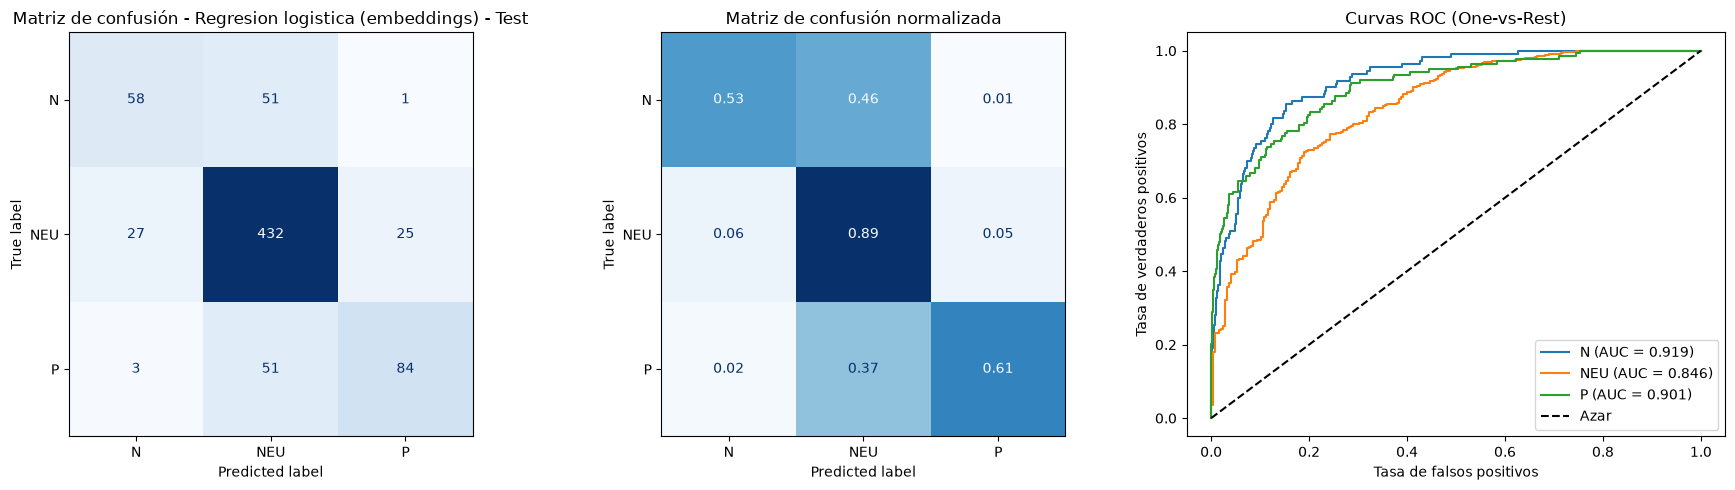

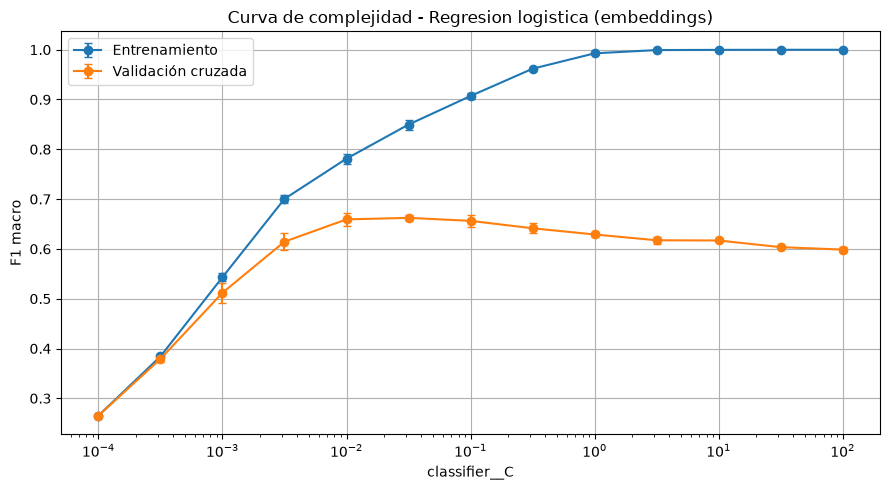

In [48]:
evaluar_modelo(best_model_lr, nombre="Regresion logistica (embeddings) - Test")
graficar_complejidad(best_model_lr, nombre="Regresion logistica (embeddings)", param_name="classifier__C", param_range = np.logspace(-4, 2, 13)) 

**Regresión logística con embeddings, en test**: F1 macro **0.704** y accuracy 0.784, muy parecido a lo que daba la CV (0.671), así que la estimación de la validación cruzada era confiable.

- El modelo es muy bueno con los neutros (recall 0.89) pero se le escapan muchos negativos (recall 0.53) y positivos (0.61): como no balancea clases, en la duda tira a `NEU`.
- **Curva de complejidad**: con C muy chico train y validación están bajos los dos (underfitting). El máximo de validación (~0.66) está alrededor de C = 0.01–0.03, justo lo que eligió el grid. Con C más grande el train llega a 1.0 y la validación baja, causando el overfitting.

===== Regresion logistica (BoW / TF-IDF) - Test =====
Accuracy:            0.6421
Precision (macro):   0.5696
Precision (weighted):0.6865
Recall (macro):      0.6301
F1 (macro):          0.5882
F1 (weighted):       0.6542
ROC-AUC (OvR macro): 0.8117   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.43      0.57      0.49       110
         NEU       0.81      0.65      0.72       484
           P       0.47      0.67      0.55       138

    accuracy                           0.64       732
   macro avg       0.57      0.63      0.59       732
weighted avg       0.69      0.64      0.65       732



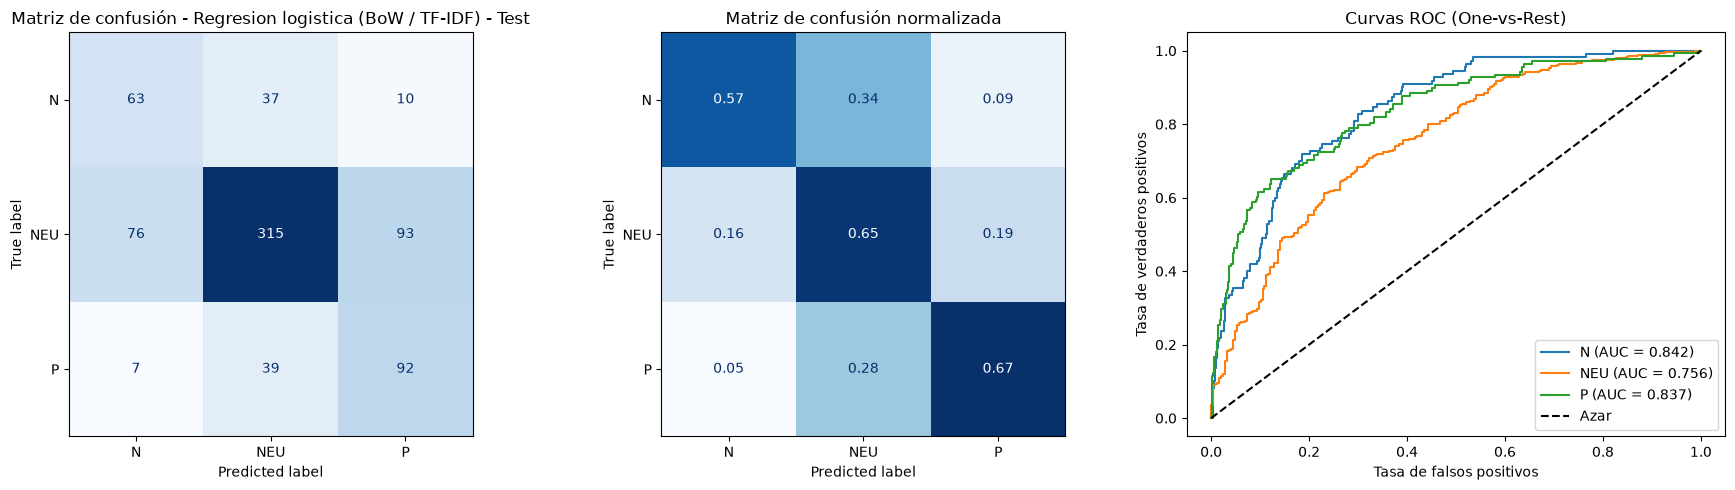

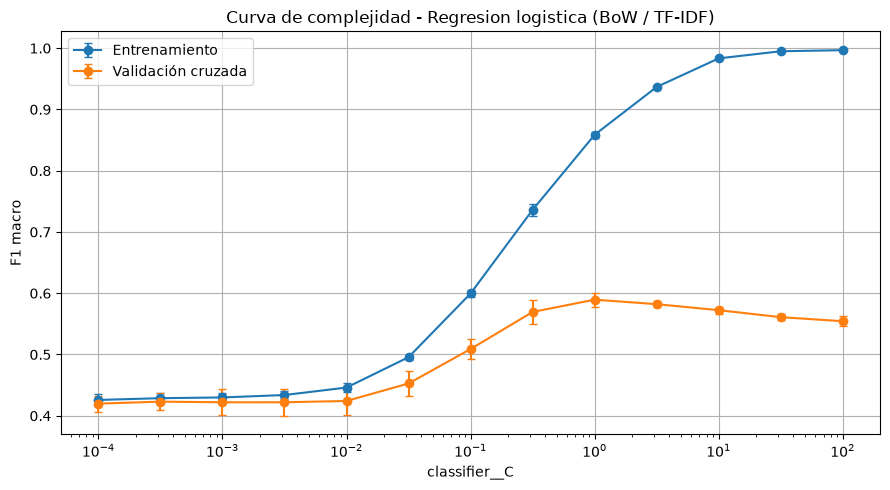

In [49]:
# Este modelo trae su propio preprocesador, por eso se evalua sobre el texto crudo
evaluar_modelo(best_model_lr_bow, nombre="Regresion logistica (BoW / TF-IDF) - Test", X=X_test, y=y_test)
graficar_complejidad(best_model_lr_bow, nombre="Regresion logistica (BoW / TF-IDF)", param_name="classifier__C",
                     param_range = np.logspace(-4, 2, 13), X=X_trval, y=y_trval)

**Regresión logística con BoW / TF-IDF, en test**: F1 macro **0.588**, coherente con la CV (0.595).

- Al usar `class_weight="balanced"` pasa lo contrario que con embeddings: sube el recall de negativos (0.57) y positivos (0.67), pero con mucha menos precisión (0.43 y 0.47). Termina marcando como opinión muchos tweets que eran neutros.
- **Curva de complejidad**: queda plana (~0.42) hasta C = 0.01, tiene el máximo en C ≈ 1 (~0.59), que fue el elegido, y a partir de ahí overfittea.

In [50]:
# Analisis de errores del mejor modelo de regresion logistica (elegido por CV)
if grid_search_lr.best_score_ >= grid_search_lr_bow.best_score_:
    nombre_lr, modelo_lr, X_eval_lr = "Embeddings", best_model_lr, X_test_prepro
else:
    nombre_lr, modelo_lr, X_eval_lr = "BoW / TF-IDF", best_model_lr_bow, X_test

y_pred_lr = modelo_lr.predict(X_eval_lr)
y_proba_lr = modelo_lr.predict_proba(X_eval_lr)

errores = pd.DataFrame({
    "texto": X_test["text"].to_numpy(),
    "real": y_test.to_numpy(),
    "predicho": y_pred_lr,
    "confianza": y_proba_lr.max(axis=1),
})
solo_errores = errores[errores["real"] != errores["predicho"]]

print(f"Modelo analizado: Regresion logistica ({nombre_lr})")
print("Errores por clase real -> predicha:")
print(solo_errores.groupby(["real", "predicho"]).size().sort_values(ascending=False).to_string())

Modelo analizado: Regresion logistica (Embeddings)
Errores por clase real -> predicha:
real  predicho
N     NEU         51
P     NEU         51
NEU   N           27
      P           25
P     N            3
N     P            1


**Análisis de errores**: casi todos los errores (102 de 132) son negativos o positivos que el modelo marcó como **neutros**. Solo hay 4 casos en que confundió negativo con positivo o al revés.

O sea, el modelo casi nunca "da vuelta" el sentimiento: lo difícil es distinguir **opinión suave vs neutral**. Tiene sentido, porque en el dataset hay muchos tweets con opiniones tibias o irónicas.

In [51]:
tweets_lr = tweets + [
    "La IA nos va a sacar el trabajo y encima lo hace mal!",
    "Increíble lo que se puede hacer con ChatGPT, me ahorra horas de trabajo",
    "Hoy se presentó una nueva herramienta de inteligencia artificial para empresas",
]

# Embeddings: usa el preprocessor compartido (comportamiento por defecto de la funcion)
resultado = predecir_tweets(best_model_lr, tweets_lr, nombre="Predicción de tweets Regresion logistica (embeddings)")

# BoW / TF-IDF: el pipeline ya preprocesa, asi que se le pasa un preprocesador identidad
resultado = predecir_tweets(best_model_lr_bow, tweets_lr, preprocessor=FunctionTransformer(), nombre="Predicción de tweets Regresion logistica (BoW / TF-IDF)")

===== Predicción de tweets Regresion logistica (embeddings) =====
                                                                         tweet prediccion      N    NEU      P
                                                  A veces funciona, a veces no        NEU 0.0153 0.8213 0.1634
                            Nos puede llegar a sacar el trabajo, es un peligro          N 0.9597 0.0373 0.0030
                                                      Es una buena herramienta        NEU 0.0003 0.6483 0.3514
   Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre          P 0.0016 0.0152 0.9832
                         La IA nos va a sacar el trabajo y encima lo hace mal!          N 0.9659 0.0245 0.0096
       Increíble lo que se puede hacer con ChatGPT, me ahorra horas de trabajo          P 0.0004 0.0106 0.9890
Hoy se presentó una nueva herramienta de inteligencia artificial para empresas        NEU 0.0039 0.6048 0.3914
===== Predicción de tweets Regresion logistica

**Comparando las dos variantes con frases inventadas**

- "*A veces funciona, a veces no*": embeddings dice `NEU` (correcto), BoW dice `N`. BoW ve la palabra "no" (que conservamos con `KEEP`) y la asocia con lo negativo sin entender la frase entera.
- "*Es una buena herramienta*": BoW dice `P` con 85%, porque ve "buena". Embeddings dice `NEU` (65%): es una frase corta y descriptiva, parecida a muchos tweets neutros del dataset.
- En las frases claras (el trabajo / un peligro, me ahorra horas) las dos aciertan, pero embeddings con mucha más seguridad (~96–99%).

Esto muestra bien la diferencia: BoW reacciona a palabras sueltas y los embeddings miran la frase completa.

## Resultados Random Forest

In [52]:
grid_search_rf.fit(X_trval, y_trval)

print("="*30)
print("Mejores parametros random forest:", grid_search_rf.best_params_)
print("Mejor score (CV):", grid_search_rf.best_score_)
print("="*30)

best_model_rf = grid_search_rf.best_estimator_

Fitting 3 folds for each of 320 candidates, totalling 960 fits


20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 799.15it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


Mejores parametros random forest: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200, 'pre__text': EmbeddingTransformer()}
Mejor score (CV): 0.6539557457086974


===== Random Forest - Test =====
Accuracy:            0.7281
Precision (macro):   0.6612
Precision (weighted):0.7370
Recall (macro):      0.6912
F1 (macro):          0.6746
F1 (weighted):       0.7314
ROC-AUC (OvR macro): 0.8448   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.59      0.68      0.63       110
         NEU       0.82      0.77      0.79       484
           P       0.58      0.62      0.60       138

    accuracy                           0.73       732
   macro avg       0.66      0.69      0.67       732
weighted avg       0.74      0.73      0.73       732



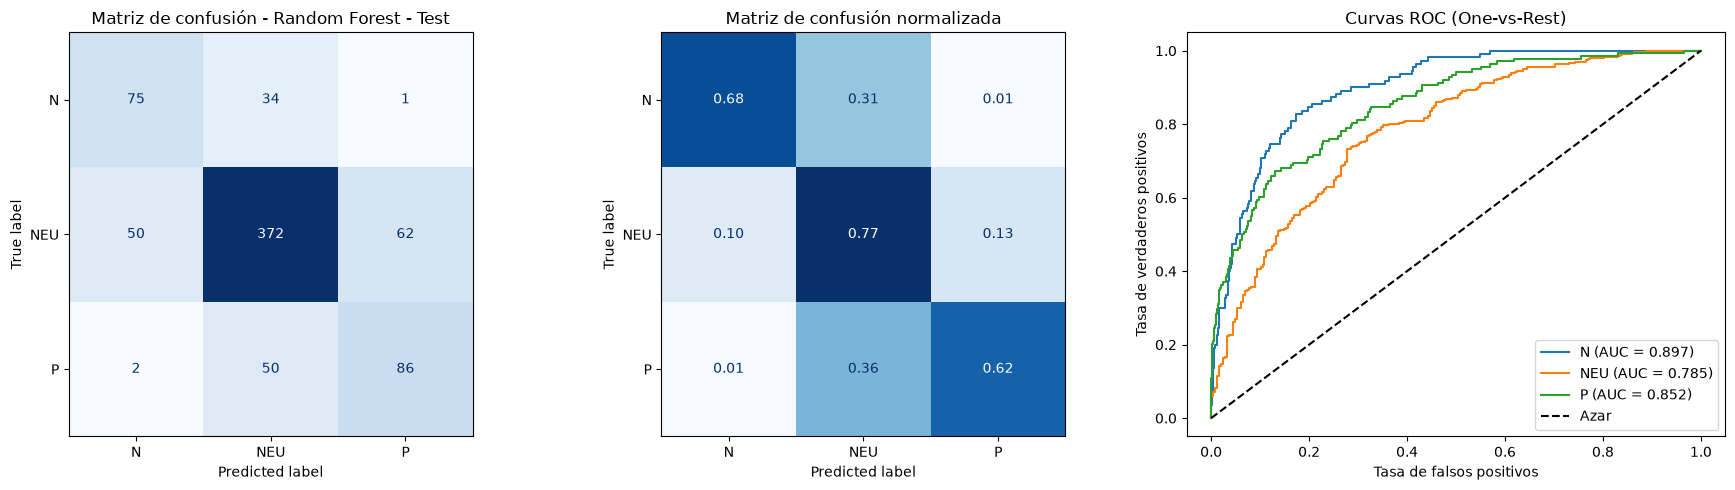

20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 995.09it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 

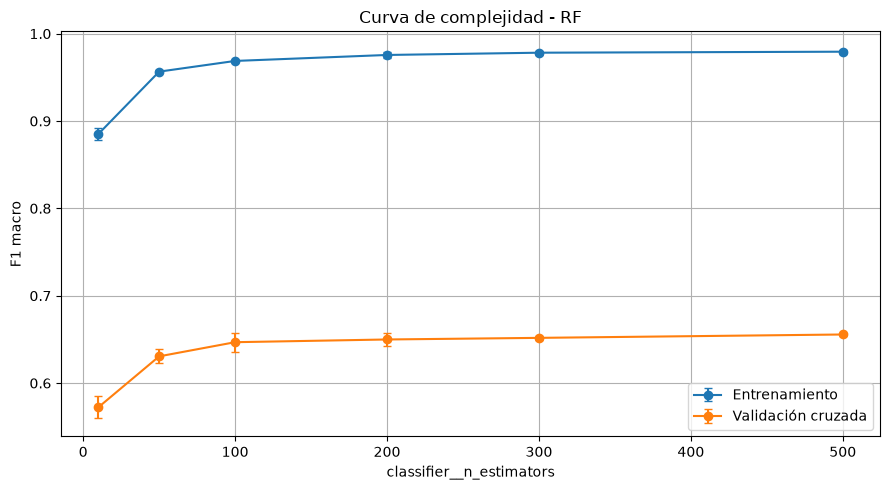

In [53]:
evaluar_modelo(best_model_rf, nombre="Random Forest - Test", X=X_test,
    y=y_test,)
graficar_complejidad(best_model_rf,nombre="RF",param_name="classifier__n_estimators",param_range=[10, 50, 100, 200, 300, 500], log_x=False, X=X_trval,
    y=y_trval, grid=grid_search_rf,)

**Random Forest en test**:

- Recall muy alto en negativos (0.75) pero con precisión de 0.39, y recall de solo 0.52 en neutros. El `class_weight="balanced"` empuja demasiado hacia las clases chicas: la mitad de los neutros terminan clasificados como opinión.
- **Curva de complejidad (n_estimators)**: la validación sube hasta ~100–200 árboles y después queda plana (~0.545), así que 200 es razonable y poner más solo agrega tiempo. La distancia entre train (~0.73) y validación (~0.55) muestra algo de overfitting, que se controla con `max_depth` y no con la cantidad de árboles.

In [54]:
# La calibración es responsabilidad de quien llama a la función
resultado_rf1 = predecir_tweets(
    best_model_rf.named_steps["classifier"],
    tweets,
    preprocessor=best_model_rf.named_steps["pre"],
    number_columns=number_columns,
    nombre="Predicción de tweets Random Forest"
)
resultado_rf2 = predecir_tweets(
    best_model_rf.named_steps["classifier"],
    tweets_lr,
    preprocessor=best_model_rf.named_steps["pre"],
    number_columns=number_columns,
    nombre="Predicción de tweets Random Forest 2"
)

===== Predicción de tweets Random Forest =====
                                                                      tweet prediccion      N    NEU      P
                                               A veces funciona, a veces no        NEU 0.2482 0.4204 0.3314
                         Nos puede llegar a sacar el trabajo, es un peligro          N 0.4332 0.3565 0.2102
                                                   Es una buena herramienta        NEU 0.2380 0.4478 0.3142
Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre          P 0.1538 0.3492 0.4969
===== Predicción de tweets Random Forest 2 =====
                                                                         tweet prediccion      N    NEU      P
                                                  A veces funciona, a veces no        NEU 0.2482 0.4204 0.3314
                            Nos puede llegar a sacar el trabajo, es un peligro          N 0.4332 0.3565 0.2102
                               

## Resultados Naive Bayes

Se ejecuta la búsqueda exhaustiva en grilla (GridSearch) para ambas representaciones.

In [55]:
# Fit de Variante 1: Embeddings + PCA
grid_search_nb_emb.fit(X_trval_prepro, y_trval)
print("="*30)
print("Mejores parametros Naive Bayes (embeddings):", grid_search_nb_emb.best_params_)
print("Mejor score (CV):", grid_search_nb_emb.best_score_)
print("="*30)
best_model_nb_emb = grid_search_nb_emb.best_estimator_

# Fit de Variante 2: BoW / TF-IDF
grid_search_nb_bow.fit(X_trval["text"], y_trval)
print("="*30)
print("Mejores parametros Naive Bayes (BoW / TF-IDF):", grid_search_nb_bow.best_params_)
print("Mejor score (CV):", grid_search_nb_bow.best_score_)
print("="*30)
best_model_nb_bow = grid_search_nb_bow.best_estimator_

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Mejores parametros Naive Bayes (embeddings): {'classifier__var_smoothing': np.float64(1e-08), 'pca__n_components': 30, 'pca__whiten': False}
Mejor score (CV): 0.5935466028798871
Fitting 3 folds for each of 48 candidates, totalling 144 fits
Mejores parametros Naive Bayes (BoW / TF-IDF): {'classifier__var_smoothing': np.float64(0.01), 'vectorizer__max_features': 1000, 'vectorizer__ngram_range': (1, 2)}
Mejor score (CV): 0.47286546857971157


## Evaluación del Rendimiento de Naive Bayes

Se miden los resultados finales en el conjunto de prueba no visto (`X_test`) evaluando **F1 Macro**, la matriz de confusión y las curvas ROC. Asimismo, se grafica la **curva de complejidad** variando `var_smoothing` para verificar el balance del modelo frente a problemas de bajo o alto sesgo / varianza (overfitting vs underfitting).

===== Naive Bayes (embeddings) - Test =====
Accuracy:            0.7336
Precision (macro):   0.6708
Precision (weighted):0.7223
Recall (macro):      0.6101
F1 (macro):          0.6343
F1 (weighted):       0.7238
ROC-AUC (OvR macro): 0.8207   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.61      0.46      0.53       110
         NEU       0.77      0.86      0.81       484
           P       0.63      0.51      0.56       138

    accuracy                           0.73       732
   macro avg       0.67      0.61      0.63       732
weighted avg       0.72      0.73      0.72       732



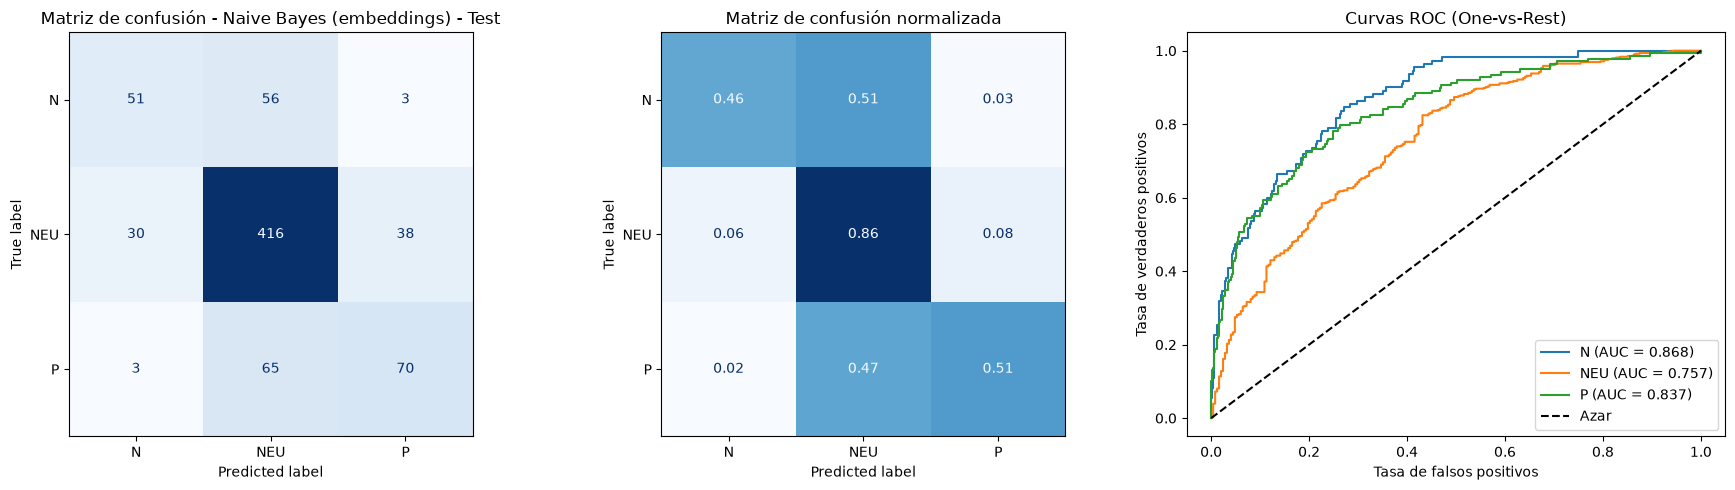

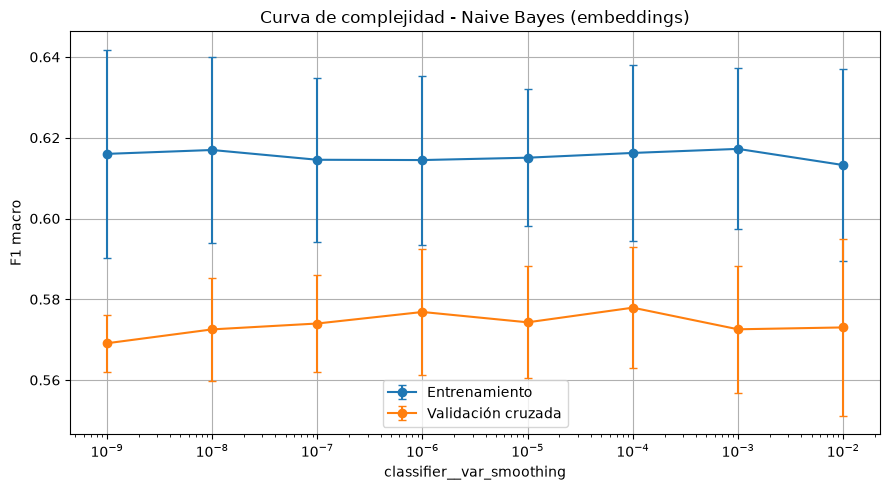

In [56]:
evaluar_modelo(best_model_nb_emb, nombre="Naive Bayes (embeddings) - Test")
graficar_complejidad(grid_search_nb_emb, nombre="Naive Bayes (embeddings)", param_name="classifier__var_smoothing")

===== Naive Bayes (BoW / TF-IDF) - Test =====
Accuracy:            0.4891
Precision (macro):   0.4733
Precision (weighted):0.6110
Recall (macro):      0.5428
F1 (macro):          0.4659
F1 (weighted):       0.5095
ROC-AUC (OvR macro): 0.7033   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.27      0.63      0.38       110
         NEU       0.75      0.44      0.55       484
           P       0.40      0.57      0.47       138

    accuracy                           0.49       732
   macro avg       0.47      0.54      0.47       732
weighted avg       0.61      0.49      0.51       732



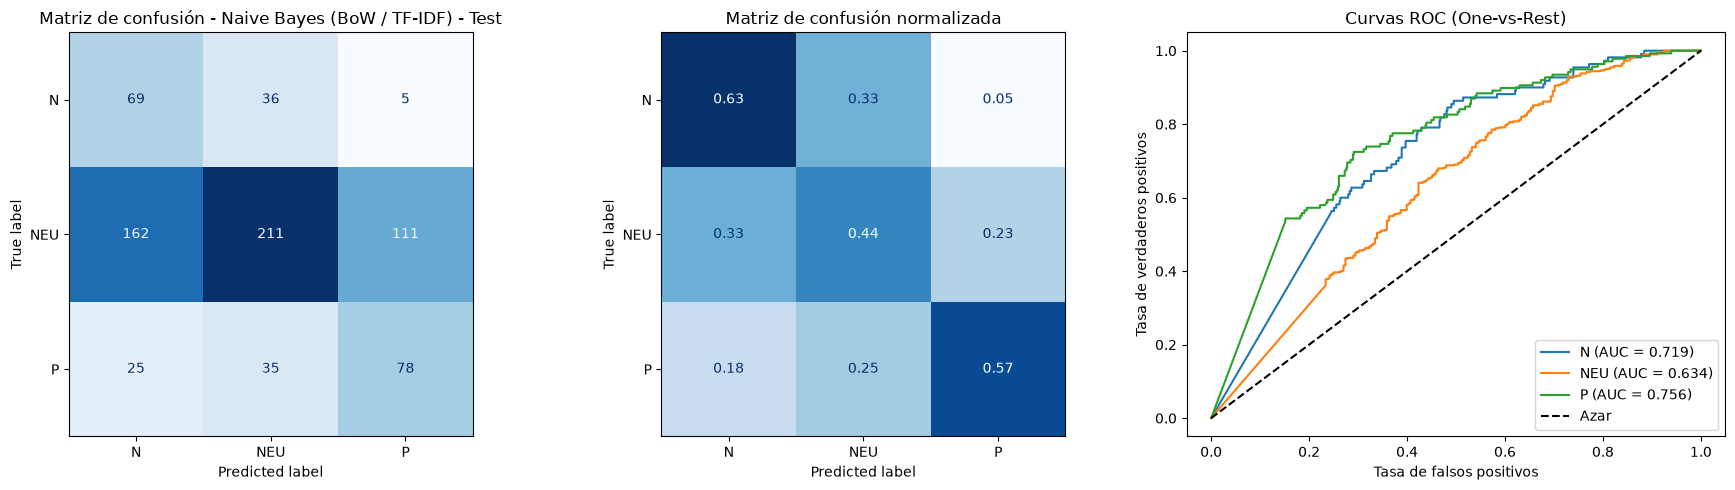

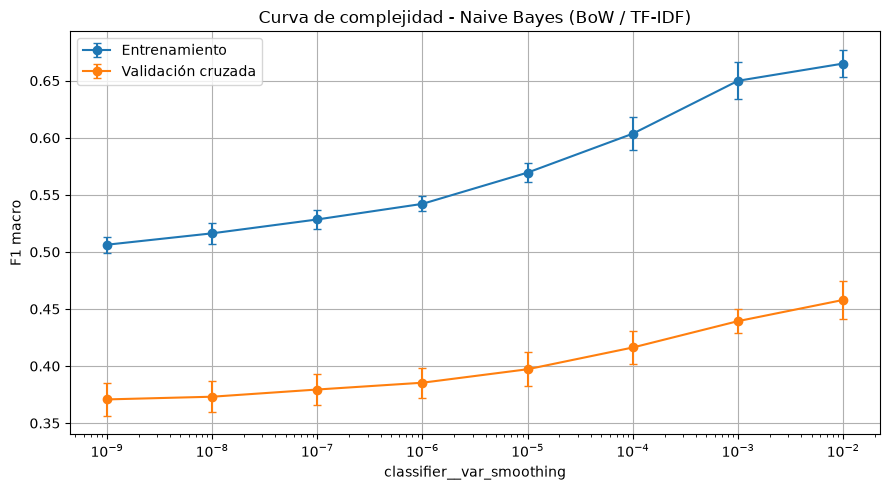

In [57]:
evaluar_modelo(best_model_nb_bow, nombre="Naive Bayes (BoW / TF-IDF) - Test", X=X_test["text"], y=y_test)
graficar_complejidad(best_model_nb_bow, nombre="Naive Bayes (BoW / TF-IDF)", param_name="classifier__var_smoothing", grid=grid_search_nb_bow, X=X_trval["text"], y=y_trval)

## Pruebas de calidad

Se realiza la predicción de sentimientos sobre tweets de prueba seleccionados para observar el comportamiento práctico de ambos pipelines ajustados frente a oraciones ambiguas, positivas o negativas

In [58]:
resultado_nb1 = predecir_tweets(best_model_nb_emb, tweets, nombre="Predicción de tweets Naive Bayes (embeddings)")
resultado_nb2 = predecir_tweets(best_model_nb_bow, tweets_lr, preprocessor=FunctionTransformer(lambda df_in: df_in["text"]),
                                nombre="Predicción de tweets Naive Bayes (BoW / TF-IDF)")

===== Predicción de tweets Naive Bayes (embeddings) =====
                                                                      tweet prediccion      N    NEU      P
                                               A veces funciona, a veces no          P 0.0323 0.4565 0.5112
                         Nos puede llegar a sacar el trabajo, es un peligro          N 0.4674 0.1985 0.3342
                                                   Es una buena herramienta        NEU 0.0275 0.5555 0.4170
Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre          P 0.0037 0.1545 0.8419
===== Predicción de tweets Naive Bayes (BoW / TF-IDF) =====
                                                                         tweet prediccion   N  NEU   P
                                                  A veces funciona, a veces no          N 1.0  0.0 0.0
                            Nos puede llegar a sacar el trabajo, es un peligro          N 1.0  0.0 0.0
                                 

## Resultados Decision Tree

20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1125.69it/s]
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
20988 | INFO | No device provided, using cpu
20988 | INFO | HTTP Request: GET https://huggingface.co/api/models/hiiamsid/sentence_similarity_spanish_es "HTTP/1.1 200 OK"
20988 | INFO | Loading SentenceTransformer model from hiiamsid/sentence_similarity_spanish_es.
Loading weights: 100%|██████████| 199/199

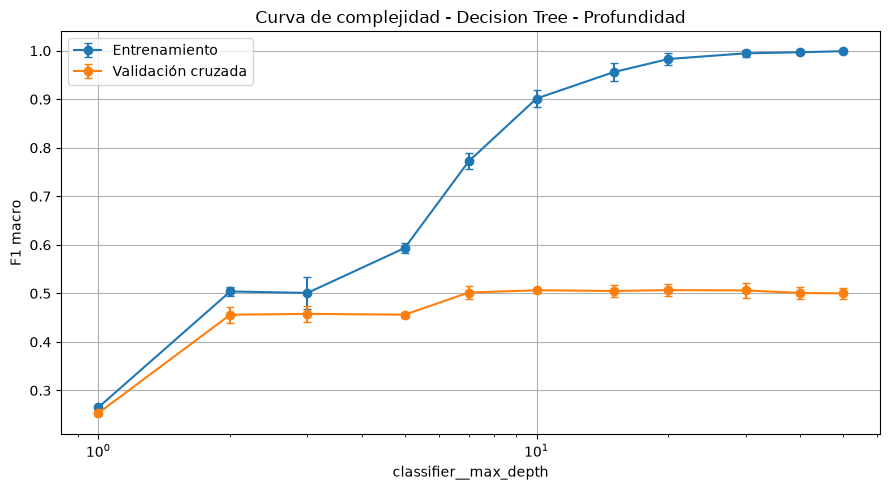

In [59]:
graficar_complejidad(pipeline_dt, nombre="Decision Tree - Profundidad", param_name="classifier__max_depth", param_range=[1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50], X=X_trval, y=y_trval,)

===== Decision Tree - Test =====
Accuracy:            0.5779
Precision (macro):   0.4958
Precision (weighted):0.6124
Recall (macro):      0.5298
F1 (macro):          0.5068
F1 (weighted):       0.5903
ROC-AUC (OvR macro): 0.6331   (usando predict_proba)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.31      0.44      0.36       110
         NEU       0.73      0.62      0.67       484
           P       0.45      0.53      0.49       138

    accuracy                           0.58       732
   macro avg       0.50      0.53      0.51       732
weighted avg       0.61      0.58      0.59       732



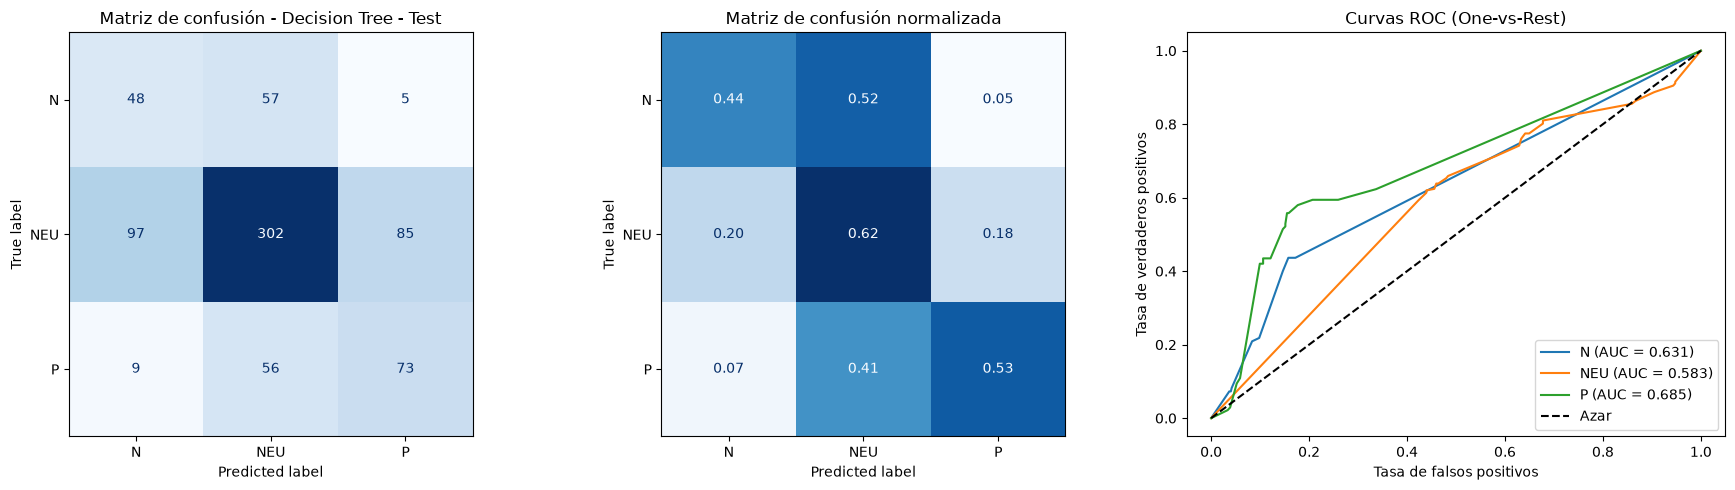

{'accuracy': 0.5778688524590164,
 'precision_macro': 0.495750638599334,
 'precision_weighted': 0.6124336659290717,
 'recall_macro': 0.5297720285862578,
 'f1_macro': 0.5068479390335717,
 'f1_weighted': 0.5903223564915698,
 'roc_auc': 0.633055707925291,
 'y_pred': array(['N', 'P', 'NEU', 'P', 'NEU', 'P', 'N', 'NEU', 'NEU', 'N', 'NEU',
        'N', 'NEU', 'N', 'P', 'N', 'P', 'N', 'NEU', 'NEU', 'NEU', 'NEU',
        'NEU', 'NEU', 'NEU', 'NEU', 'P', 'N', 'NEU', 'P', 'P', 'P', 'N',
        'N', 'N', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'N', 'P', 'NEU',
        'NEU', 'N', 'P', 'NEU', 'NEU', 'NEU', 'P', 'N', 'P', 'NEU', 'NEU',
        'P', 'NEU', 'NEU', 'N', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'P',
        'NEU', 'P', 'NEU', 'NEU', 'NEU', 'P', 'NEU', 'NEU', 'N', 'P',
        'NEU', 'NEU', 'NEU', 'NEU', 'N', 'NEU', 'NEU', 'P', 'NEU', 'NEU',
        'N', 'NEU', 'P', 'P', 'NEU', 'NEU', 'N', 'NEU', 'N', 'NEU', 'NEU',
        'NEU', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'P', 'N',
        

In [60]:
evaluar_modelo(pipeline_dt, nombre="Decision Tree - Test", X=X_test, y=y_test)

In [61]:
resultado_dt = predecir_tweets(
    pipeline_dt.named_steps["classifier"],
    tweets,
    preprocessor=pipeline_dt.named_steps["pre"],
    number_columns=number_columns,
    nombre="Predicción de decision tree"
)

===== Predicción de decision tree =====
                                                                      tweet prediccion     N    NEU      P
                                               A veces funciona, a veces no        NEU 0.000 1.0000 0.0000
                         Nos puede llegar a sacar el trabajo, es un peligro          N 0.878 0.1115 0.0105
                                                   Es una buena herramienta          P 0.000 0.0000 1.0000
Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre          P 0.000 0.1432 0.8568


## Conclusiones

In [62]:
# Comparacion final de todos los modelos (CV sobre train+val y F1 macro en test)
modelos_finales = {
    "Red neuronal": (grid_search_nn, X_test_prepro),
    "SVM": (grid_search_svm, X_test_prepro),
    "Regresion logistica (embeddings)": (grid_search_lr, X_test_prepro),
    "Regresion logistica (BoW / TF-IDF)": (grid_search_lr_bow, X_test),
    "Random Forest": (grid_search_rf, X_test),
    "Naive Bayes (embeddings)": (grid_search_nb_emb, X_test_prepro),
    "Naive Bayes (BoW / TF-IDF)": (grid_search_nb_bow, X_test["text"]),
    "Decision Tree": (grid_search_dt, X_test),
}

comparacion = pd.DataFrame({
    nombre: {
        "F1 macro (CV)": grid.best_score_,
        "F1 macro (test)": f1_score(y_test, grid.best_estimator_.predict(X_eval), average="macro"),
    }
    for nombre, (grid, X_eval) in modelos_finales.items()
}).T.sort_values("F1 macro (CV)", ascending=False)

print(comparacion.round(4))
print("Mejor modelo segun CV:", comparacion.index[0])

                                    F1 macro (CV)  F1 macro (test)
SVM                                        0.6977           0.6846
Red neuronal                               0.6799           0.7001
Regresion logistica (embeddings)           0.6714           0.7040
Random Forest                              0.6540           0.6746
Regresion logistica (BoW / TF-IDF)         0.5946           0.5882
Naive Bayes (embeddings)                   0.5935           0.6343
Decision Tree                              0.5004           0.5068
Naive Bayes (BoW / TF-IDF)                 0.4729           0.4659
Mejor modelo segun CV: SVM


### Conclusiones

**1. La representación del texto importa más que el algoritmo.** Los tres modelos con embeddings (SVM, red neuronal, regresión logística) quedan todos entre 0.67 y 0.70 de F1 macro. Todos los que usan BoW / TF-IDF quedan entre 0.47 y 0.59, sin importar el algoritmo. Cambiar de modelo mueve 1 o 2 puntos; cambiar la representación mueve 10.

**2. La CV fue una buena guía.** En todos los modelos el F1 de test quedó cerca del de validación cruzada (diferencias de ~0.01–0.03). Eso quiere decir que no sobreajustamos los hiperparámetros a los folds y que los números son creíbles.

**3. ¿Cuál elegimos?** Por validación cruzada, el mejor es la **SVM** (0.698). En test la regresión logística sacó un poco más (0.704 contra 0.685), pero **no elegimos mirando el test**: si lo hiciéramos, el test dejaría de ser una estimación honesta. Además, con 732 tweets de test, diferencias de 1–2 puntos están dentro del ruido. Una alternativa razonable sería la regresión logística: rinde casi igual y es mucho más simple y rápida.

**4. Lo que más le cuesta a todos los modelos** es separar opiniones tibias de tweets neutros. Casi nunca confunden positivo con negativo.

**5. Las variables numéricas aportan poco** (ver el análisis de importancias al final): casi toda la información está en el texto.

## En esta seccion se arma un ensamble del tipo Votting Classifier

In [63]:
from sklearn.ensemble import VotingClassifier


class KerasClassifierCompat(KerasClassifier):
    def __sklearn_tags__(self):
        tags = super().__sklearn_tags__()
        tags.estimator_type = "classifier"
        return tags


mejor_svm = OneVsRestClassifier(
    SVC(
        C=2, kernel="rbf", gamma="scale", class_weight="balanced",
        probability=True, random_state=42,
    )
)

mejor_red_neuronal = KerasClassifierCompat(
    model=build_model,
    epochs=3,
    batch_size=32,
    verbose=0,
    model__units=256,
    model__n_layers=2,
    model__dropout=0.3,
    model__activation="sigmoid",
    model__learning_rate=0.01,
)

mejor_regresion_logistica = LogisticRegression(
    C=0.03, class_weight=None, max_iter=3000, random_state=42
)

mejor_random_forest = RandomForestClassifier(
    n_estimators=300,
    criterion="entropy",
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=5,
    max_features="log2",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

modelos = [
    ("svm", mejor_svm),
    ("red_neuronal", mejor_red_neuronal),
    ("regresion_logistica", mejor_regresion_logistica),
    ("random_forest", mejor_random_forest),
]

voting_soft = VotingClassifier(estimators=modelos, voting="hard")


C:\Users\nicky\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\nicky\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\nicky\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\nicky\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The

{'voting': 'hard', 'weights': [2, 2, 1, 1]}
0.6820231441321836
===== Voting Classifier (SVM + Red neuronal + Regresión logística + Random Forest) - Test =====
Accuracy:            0.7828
Precision (macro):   0.7400
Precision (weighted):0.7810
Recall (macro):      0.6984
F1 (macro):          0.7147
F1 (weighted):       0.7789
ROC-AUC: no disponible (el modelo no tiene predict_proba ni decision_function)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.63      0.64      0.63       110
         NEU       0.82      0.87      0.84       484
           P       0.77      0.59      0.67       138

    accuracy                           0.78       732
   macro avg       0.74      0.70      0.71       732
weighted avg       0.78      0.78      0.78       732



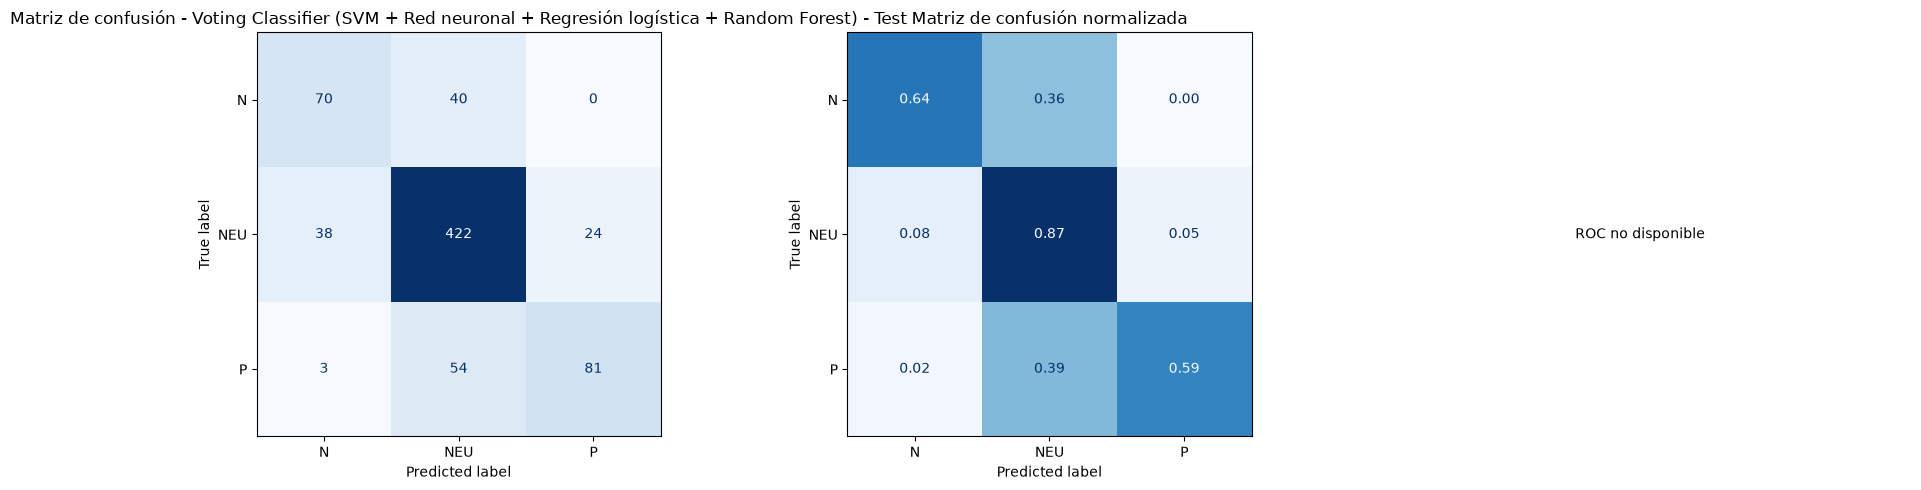

{'accuracy': 0.7827868852459017,
 'precision_macro': 0.7399628864745144,
 'precision_weighted': 0.7809507781295811,
 'recall_macro': 0.6984069948496826,
 'f1_macro': 0.7147169431875313,
 'f1_weighted': 0.7789334124570383,
 'roc_auc': None,
 'y_pred': array(['NEU', 'P', 'NEU', 'P', 'NEU', 'NEU', 'N', 'NEU', 'NEU', 'P',
        'NEU', 'N', 'NEU', 'NEU', 'NEU', 'N', 'NEU', 'NEU', 'NEU', 'P',
        'N', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'N', 'NEU', 'NEU',
        'P', 'P', 'N', 'P', 'NEU', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU',
        'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'P', 'NEU', 'NEU', 'NEU',
        'NEU', 'P', 'NEU', 'NEU', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU',
        'N', 'P', 'NEU', 'N', 'N', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU',
        'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'P', 'N', 'NEU', 'NEU',
        'NEU', 'P', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'P', 'NEU', 'NEU',
        'N', 'NEU', 'NEU', 'P', 'NEU', 'N', 'NEU', 'NEU', 'NEU', 'NEU',
        'NEU', 'NEU',

In [64]:
param_grid = {
    'voting': ['hard', 'soft'],
    'weights': [
        [2, 2, 1, 1],
        [2, 1, 2, 1],
        [2, 1, 1, 2],
        [1, 2, 2, 1],
        [1, 2, 1, 2],
        [1, 1, 2, 2]
    ]
}

grid_search = GridSearchCV(
    estimator=voting_soft,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=1
)

grid_search.fit(X_trval_prepro, y_trval)

print(grid_search.best_params_)
print(grid_search.best_score_)

evaluar_modelo(
    grid_search,
    nombre="Voting Classifier (SVM + Red neuronal + Regresión logística + Random Forest) - Test",
)


In [65]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'voting': 'hard', 'weights': [2, 2, 1, 1]}
0.6820231441321836


In [66]:
resultado_voting = predecir_tweets(
    grid_search,
    tweets,
    nombre="Predicción de tweets Voting Classifier",
)


===== Predicción de tweets Voting Classifier =====
(el modelo no tiene predict_proba ni decision_function; solo se muestran predicciones)
                                                                      tweet prediccion
                                               A veces funciona, a veces no        NEU
                         Nos puede llegar a sacar el trabajo, es un peligro          N
                                                   Es una buena herramienta        NEU
Es un avance tecnologico muy bueno para ambitos productivos, lo uso siempre          P


## Seccion de analisis de importancias

In [67]:
modelos = {
    "Random Forest": grid_search_rf.best_estimator_,
    # Estos modelos se entrenaron sobre X_trval_prepro: se les antepone el preprocessor
    # ya ajustado para que reciban X_test crudo y la importancia quede por columna original
    "SVM": Pipeline([("pre", preprocessor), ("model", grid_search_svm.best_estimator_)]),
    "Regresion Logistica": Pipeline([("pre", preprocessor), ("model", grid_search_lr.best_estimator_)]),
    "Red Neuronal": Pipeline([("pre", preprocessor), ("model", grid_search_nn.best_estimator_)]),
}

from sklearn.inspection import permutation_importance

importancias_modelos = {}

for nombre, modelo in modelos.items():

    resultado = permutation_importance(
        modelo,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importancias_modelos[nombre] = resultado.importances_mean

C:\Users\nicky\PycharmProjects\Tp_tweets\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


**¿Qué variables usan realmente los modelos?** Usamos **permutation importance**: se desordena al azar una columna del test (por ejemplo, se mezclan los textos entre tweets) y se mide cuánto cae el F1 macro. Si cae mucho, el modelo dependía de esa columna; si no cambia, no la estaba usando.

Elegimos este método porque:
- Funciona con cualquier modelo (SVM, red, RF...), así que podemos comparar todos con la misma vara.
- Trabaja sobre las **columnas originales**. El texto cuenta como una sola columna aunque adentro sean 768 dimensiones de embedding. Por eso a los modelos entrenados sobre `X_trval_prepro` les anteponemos el `preprocessor`.
- Se calcula sobre el **test** y se repite 10 veces para que no dependa de una sola mezcla al azar.

In [68]:
df_importancias = pd.DataFrame(
    importancias_modelos,
    index=X_test.columns
)

df_importancias["Promedio"] = df_importancias.mean(axis=1)

df_importancias = df_importancias.sort_values(
    by="Promedio",
    ascending=False
)

display(df_importancias)

,Random Forest,SVM,Regresion Logistica,Red Neuronal,Promedio
text,0.342486,0.343838,0.359988,0.367083,0.353349
emoji_neg,0.000000,0.001083,0.009838,0.003297,0.003555
emoji_pos,0.001423,0.003670,0.011073,-0.004562,0.002901
url_count,0.001328,0.001462,0.001205,-0.002207,0.000447
hashtag_count,0.000604,-0.003496,0.002068,0.000117,-0.000177
favorite_count,0.000000,0.000566,0.000257,-0.002342,-0.000380
retweet_count,0.000000,0.000643,0.000027,-0.002256,-0.000397
interrogation_count,-0.000113,-0.005506,0.002652,0.001305,-0.000415
exclamation_count,0.001719,-0.005962,0.000694,-0.000110,-0.000915
user_favourites_count,-0.002821,-0.002829,-0.000522,0.000688,-0.001371


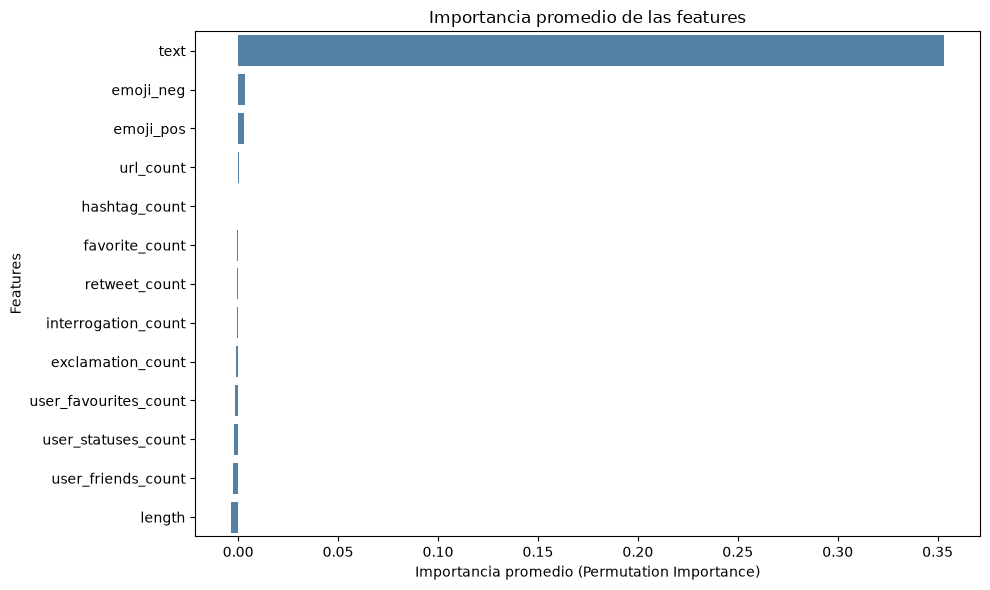

In [69]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_importancias.reset_index(),
    x="Promedio",
    y="index",
    color="steelblue"
)

plt.title("Importancia promedio de las features")
plt.xlabel("Importancia promedio (Permutation Importance)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

**Conclusión de las importancias**: el texto es de lejos lo más importante. Desordenarlo baja el F1 macro ~0.31 en promedio (~0.35 en SVM, regresión logística y red neuronal, ~0.18 en Random Forest). Todas las demás variables están por debajo de 0.01, y varias dan **negativo** (desordenarlas mejora un poquito el resultado), lo que significa que para el modelo eran básicamente ruido.

Lo poco que aportan viene de las variables que en el análisis exploratorio ya mostraban diferencias entre clases (exclamaciones, emojis positivos y negativos, URLs). Las del usuario (`user_friends_count`, `user_favourites_count`, `user_statuses_count`) no aportan nada. Esto confirma lo que dijimos en las conclusiones: el sentimiento está en lo que dice el tweet, no en sus metadatos.